# mlfilter-scale: ソルバー単体の比較(固定 FM)

同じ固定 FM(L ごとに 5 本)に対して、ペナルティ付き SA(α を変える)、ランダム提案 + FM 選択、ペナルティ不要の XY-FMQAOA(p=1〜3)、通常 QAOA(X ミキサー + ペナルティ、L=6 のみ)が、FM の良い候補をどれだけ出せるかを比べる。目的は、大きいペナルティでエネルギー地形が平準化し SA の探索がランダムに近づくことを示し、XY-FMQAOA の動機にすること。

- 入力: 各 run の `raw/summary.json`(`analysis_config.json` に SHA-256)。条件は `experiments/mlfilter-scale/solver_fixedfm.json`
- 集計: FM ごとに 10 reps の平均、5 FM の中央値(SA は IQR を灰色の帯で表示)。探索用の 5 FM で、検定はしない
- 図の作り方は `plot.py` と同じ関数を使う。CSV だけから再描画できる(`python plot.py --replot`)

In [1]:
import sys, json
from pathlib import Path
HERE = Path.cwd(); sys.path.insert(0, str(HERE))
import plot, matplotlib
print('python', sys.executable, '| matplotlib', matplotlib.__version__)
from IPython.display import Image, display
if all((plot.PROJECT/item['summary']).exists() for item in plot.CONFIG['inputs']):
    plot.build_csv()   # run summaries -> csv/ (input SHA-256 is checked)
else:
    print('Using verified CSVs in csv/ (raw run summaries are stored on server/archive)')
for item in plot.CONFIG['inputs']: print(item['layers'], item['run_dir'], item['sha256'][:16])

python /opt/homebrew/opt/python@3.14/bin/python3.14 | matplotlib 3.10.9
Using verified CSVs in csv/ (raw run summaries are stored on server/archive)
6 data/runs/mlfilter-scale/c-3b78e12aec76/r-28b3bfcef49f 27a14270f2342cf4
7 data/runs/mlfilter-scale/c-a2f92285dfd0/r-226968e37961 c0eb5f1dc504d568
8 data/runs/mlfilter-scale/c-6bf5d166318b/r-6b014cb25334 3896ba4da018518a
6 data/runs/mlfilter-scale/c-250d1b0a7b0c/r-4298770ebd51 0d469e00c3687c26
7 data/runs/mlfilter-scale/c-87cd65d36fa8/r-5f01be92933a 4b6c49aca9eaf206
8 data/runs/mlfilter-scale/c-608f29f44601/r-c1ff80c81b16 3a167fdd749c800c


## 図 1: エネルギー地形の平準化(`penalty_flattening_cvar10`)

- 横軸: ペナルティ係数 α(対数)。λ = α S、S は FM の Ising 係数の最大絶対値
- 縦軸: SA などが出した実行可能なサンプルの FM 百分位の平均。0 は FM 最良、0.5 は一様ランダムと同じ。小さいほど FM の良い候補を出している
- 黒線と点: SA の 5 FM の中央値、灰色の帯: IQR。灰色破線: ランダム提案(一様な実行可能ラベル)。青の水平線: XY-FMQAOA(λ=0 なので α によらない)。p は明るい点線→濃い破線の順に深い。線の左端のラベルで p を示し、値がほぼ同じ深さは 1 つのラベルにまとめた
- (a)(b)(c) は L = 6, 7, 8
- 見るところ: α を上げると SA の曲線が 0 から 0.5(ランダム)へ上がる。XY の線は α によらず一定で、p を深くすると下がる
- 限界: α=0.3 は L=6・8 で実行可能なサンプルがなく点がない。XY は CVaR10 目的、1024 回の角度探索、理想シミュレーション。mean 目的の版は `penalty_flattening_mean`

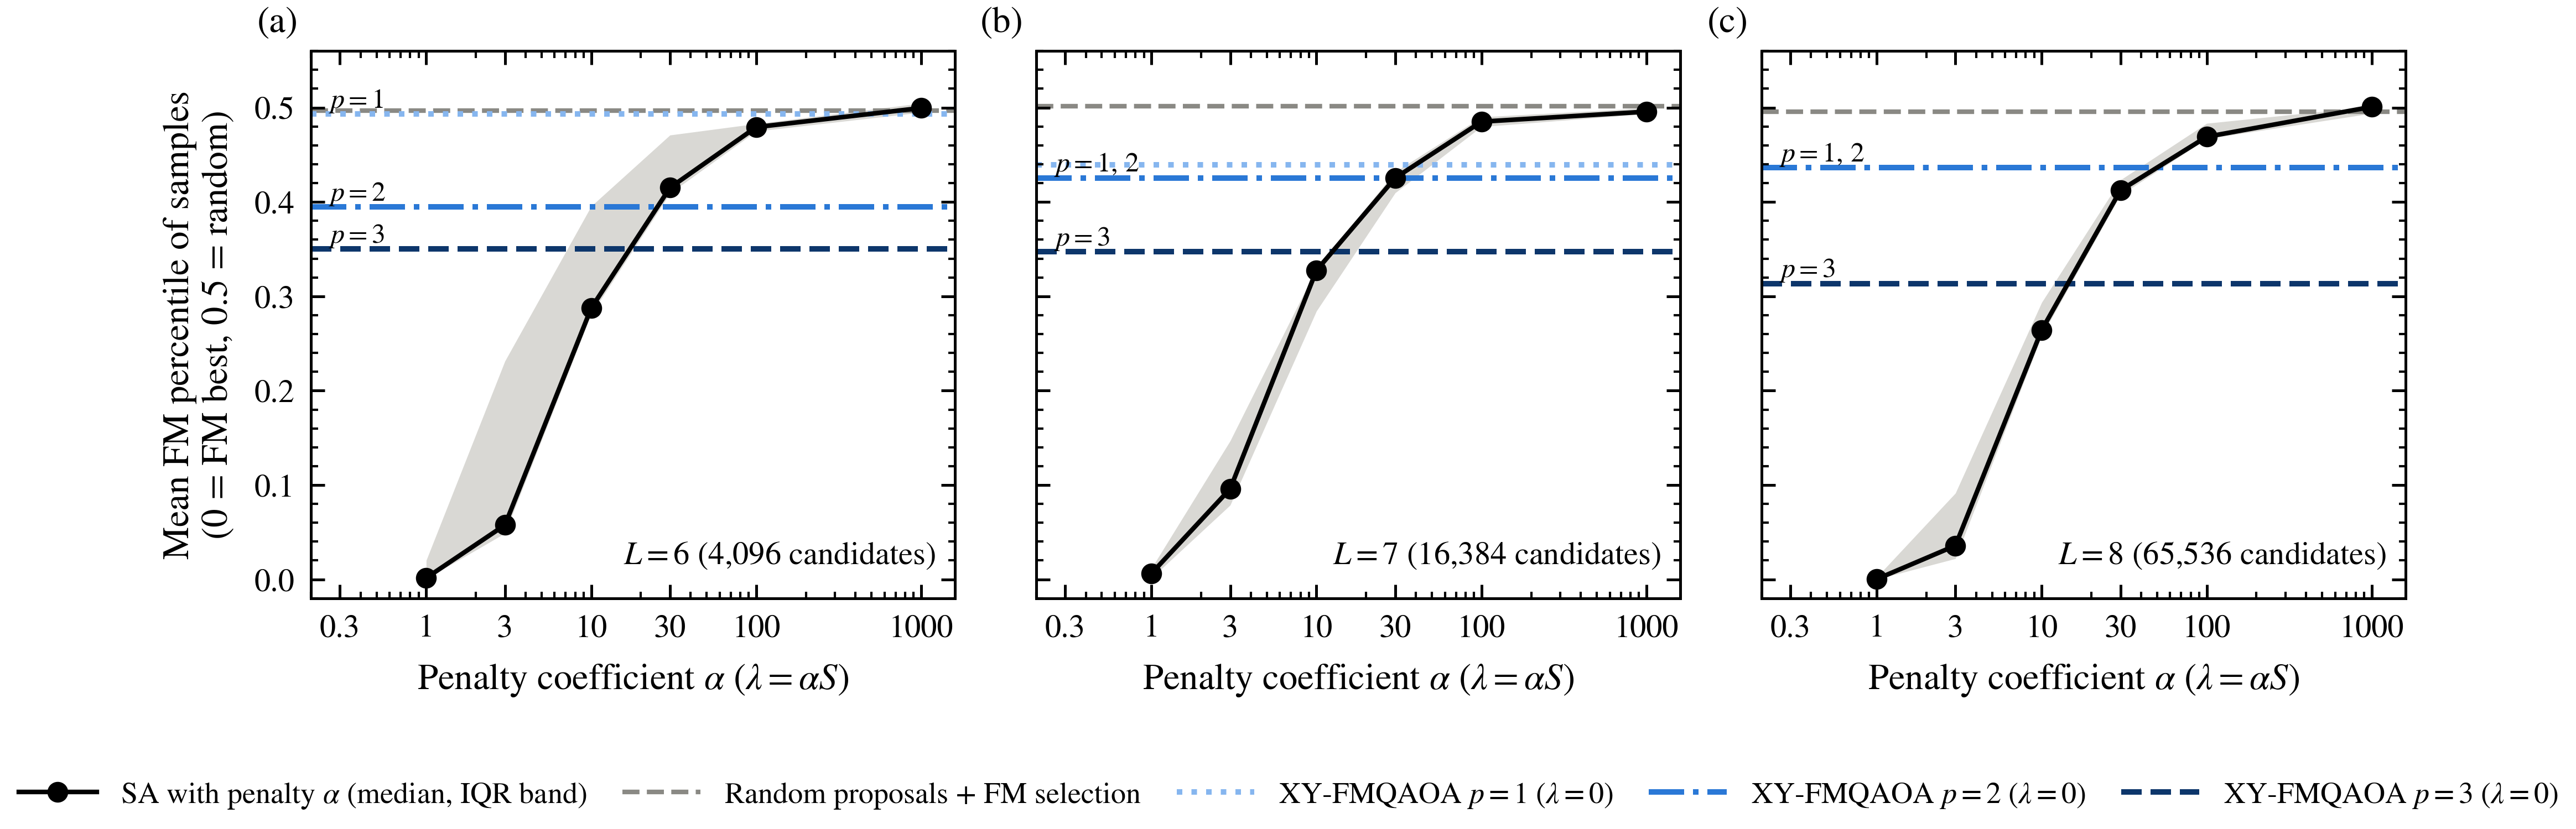

In [2]:
plot.fig_flattening('cvar10'); display(Image('png/penalty_flattening_cvar10.png'))

## 図 2: 選ばれた候補の FM のずれ(`penalty_selected_gap_cvar10`)

- 縦軸: 100 サンプルから FMQA の選択規則(新規の実行可能候補のうち FM 最小)で選んだ候補と、未評価の FM 最小解との FM の差を、未評価候補の FM の幅で割った値。0 は FM 最小解そのもの。小さいほど良い
- 線と帯は図 1 と同じ。α=0.3 は L=6・8 で候補が出ないため α≥1 のみ
- 見るところ: α=1〜3 の SA はほぼ 0。α≥30 ではランダム提案(灰色破線)と同程度。XY p=3 はランダムや大きい α の SA より小さいが、α=1〜3 の SA には届かない
- 限界: 5 FM の探索結果。XY の p=1 と p=2 が同じ値になる L があるのは、p=2 の探索で p=1 の最良角度より良い点が見つからなかったため

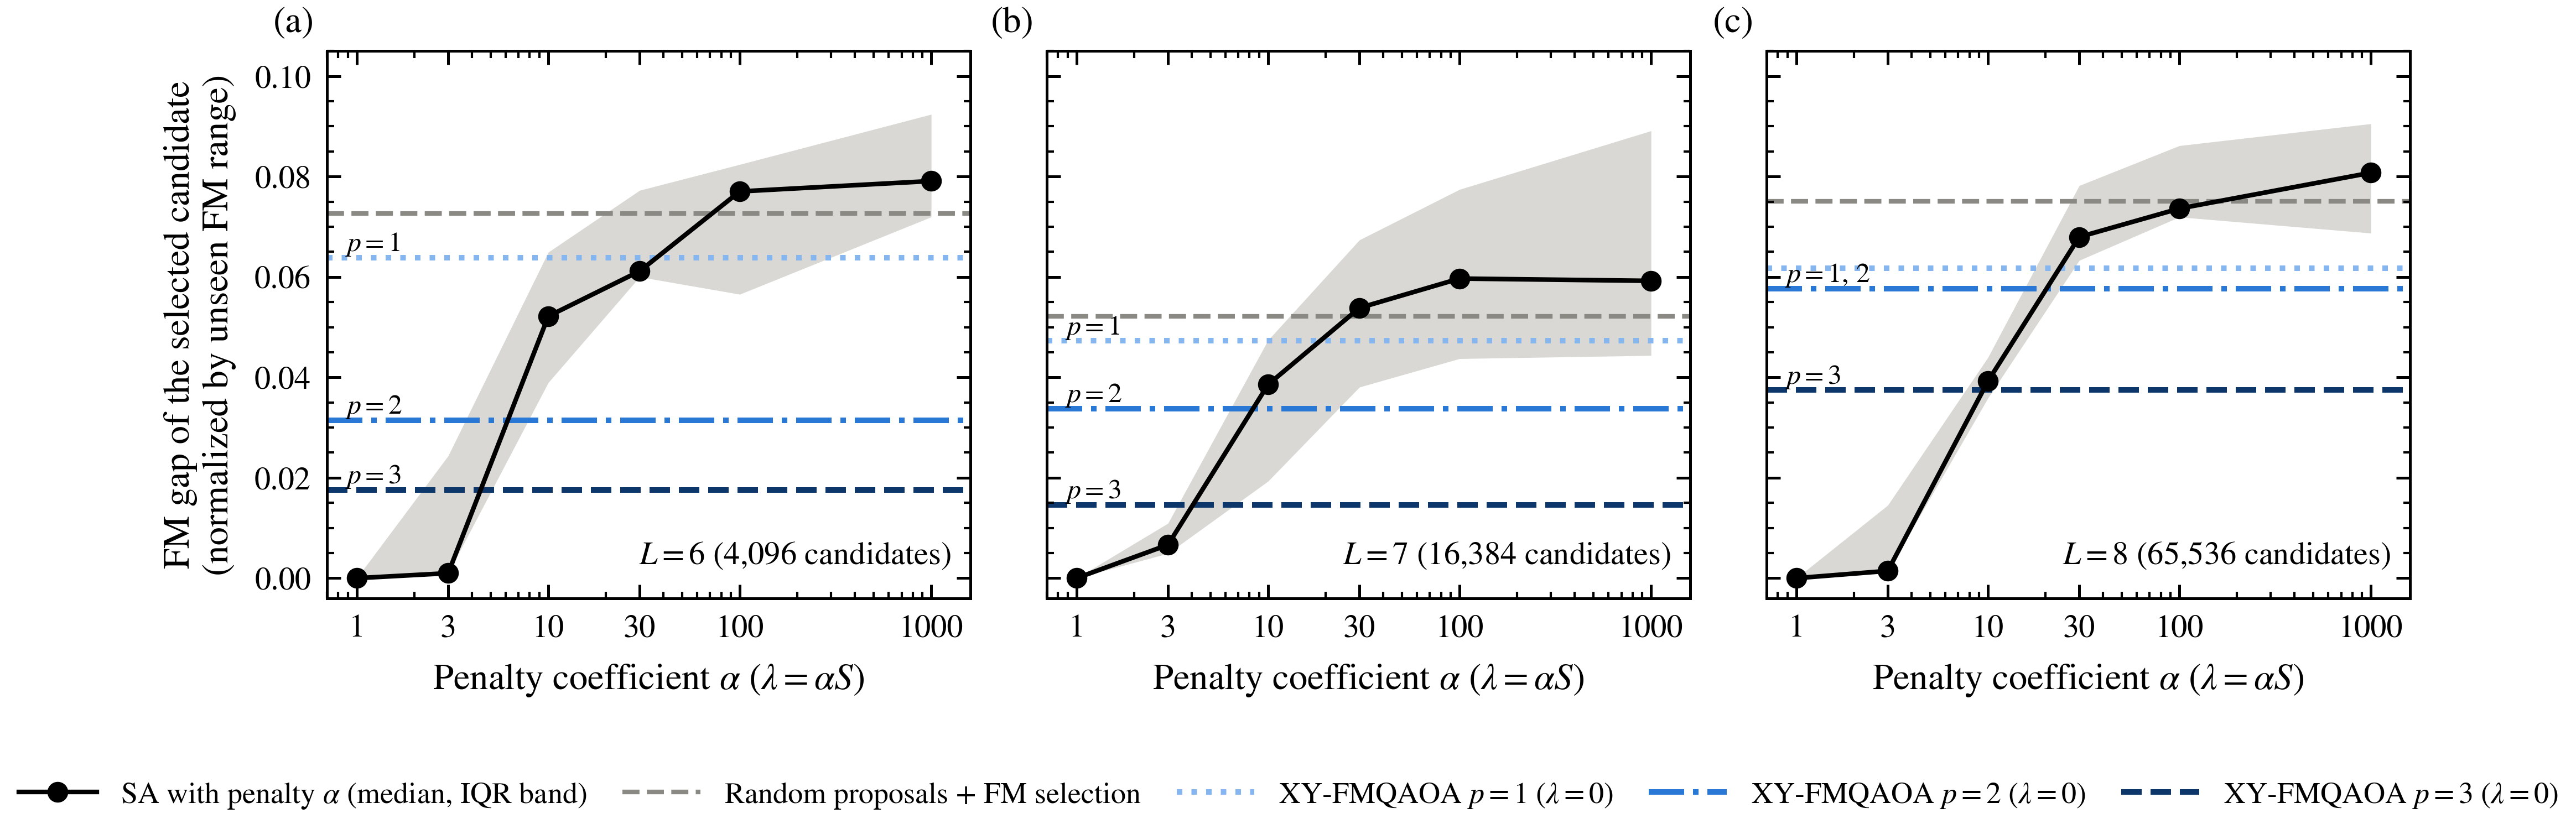

In [3]:
plot.fig_gap('cvar10'); display(Image('png/penalty_selected_gap_cvar10.png'))

## 図 3: 平準化の仕組み(`penalty_mechanism`)

- 横軸: SA が凍結する温度での FM のコントラスト ΔE_FM/λ(対数)。ΔE_FM は 1 層だけ材料を変えた実行可能な近傍どうしの FM 差の中央値。Neal の SA では実行可能な状態間の移動に違反状態(コスト λ)を経由するため、温度が λ 程度まで下がると移動が止まる。このときの FM の差が熱揺らぎの何分の 1 かを表す(∝ 1/α)
- 縦軸: 図 1 と同じ。点は FM 1 本(10 reps の平均)、色と形は L
- 見るところ: L が違っても点が 1 本の曲線に乗る。ΔE_FM/λ が約 0.1 を下回ると FM の差が見えなくなり、0.01 以下でランダム(0.5)になる
- 限界: Neal の自動 β 範囲を使った SA の挙動。他のソルバーや手動の温度設定では閾値が変わる

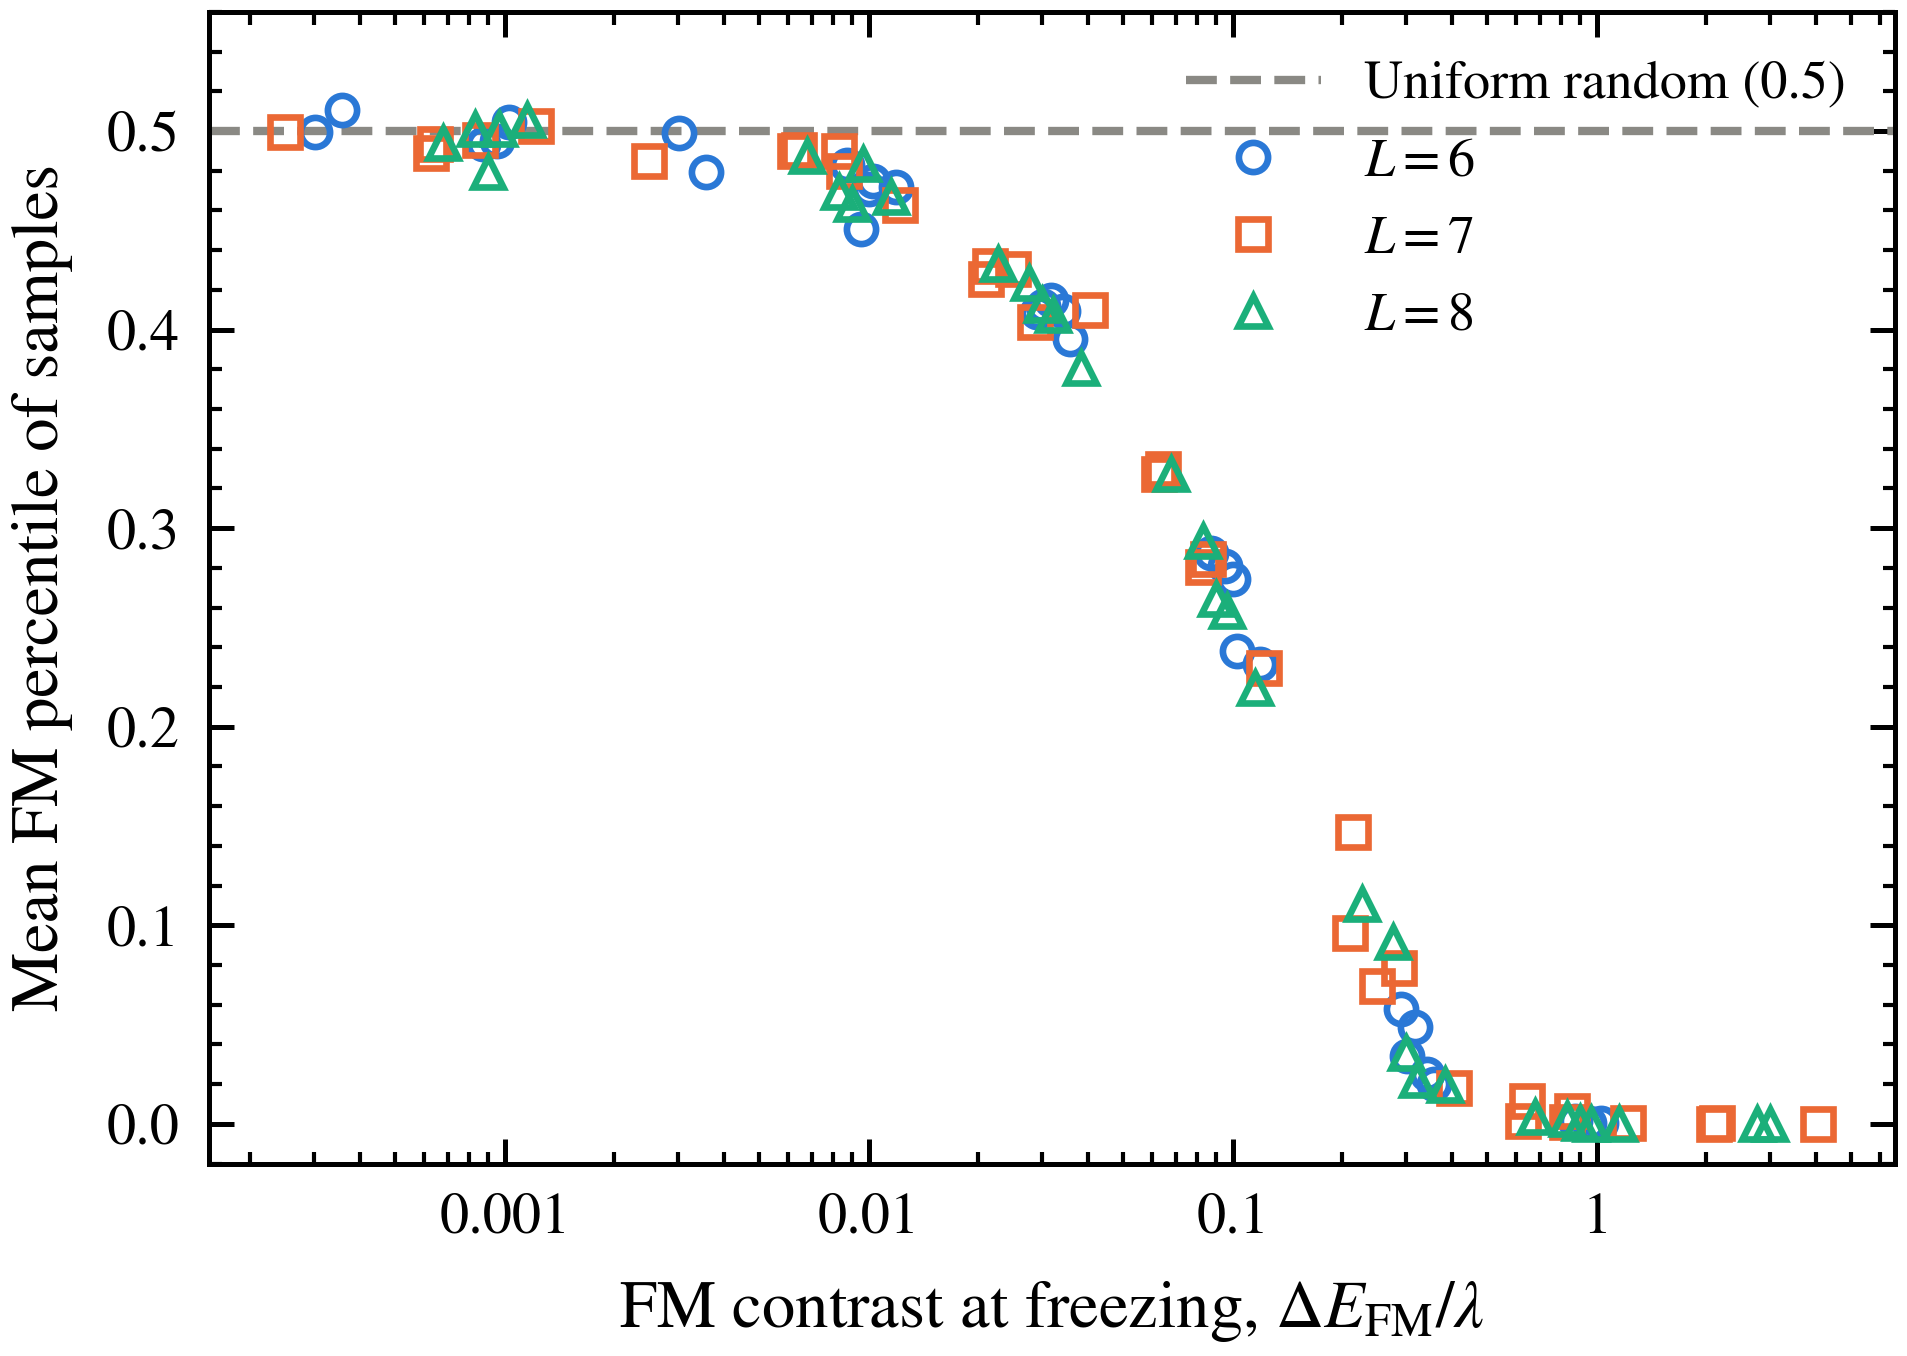

In [4]:
plot.fig_mechanism(); display(Image('png/penalty_mechanism.png'))

## 図 4: 実行可能率(`penalty_feasibility`)

- 縦軸: 100 サンプルのうち One-Hot 制約を満たす割合(大きいほど良い)
- 線: SA(L ごとの色・形、中抜き)。× 印: 通常 QAOA(X ミキサー + ペナルティ、L=6、49 格子)。濃い青破線: XY-FMQAOA(全 L・p で 1.0)
- 見るところ: α が小さい(0.3)と SA は違反ばかりになる。通常 QAOA は α=1・10・100 のどれでも実行可能率がほぼ 0。XY は構造上つねに 1.0
- 限界: 通常 QAOA は L=6・p=1・49 格子のみ

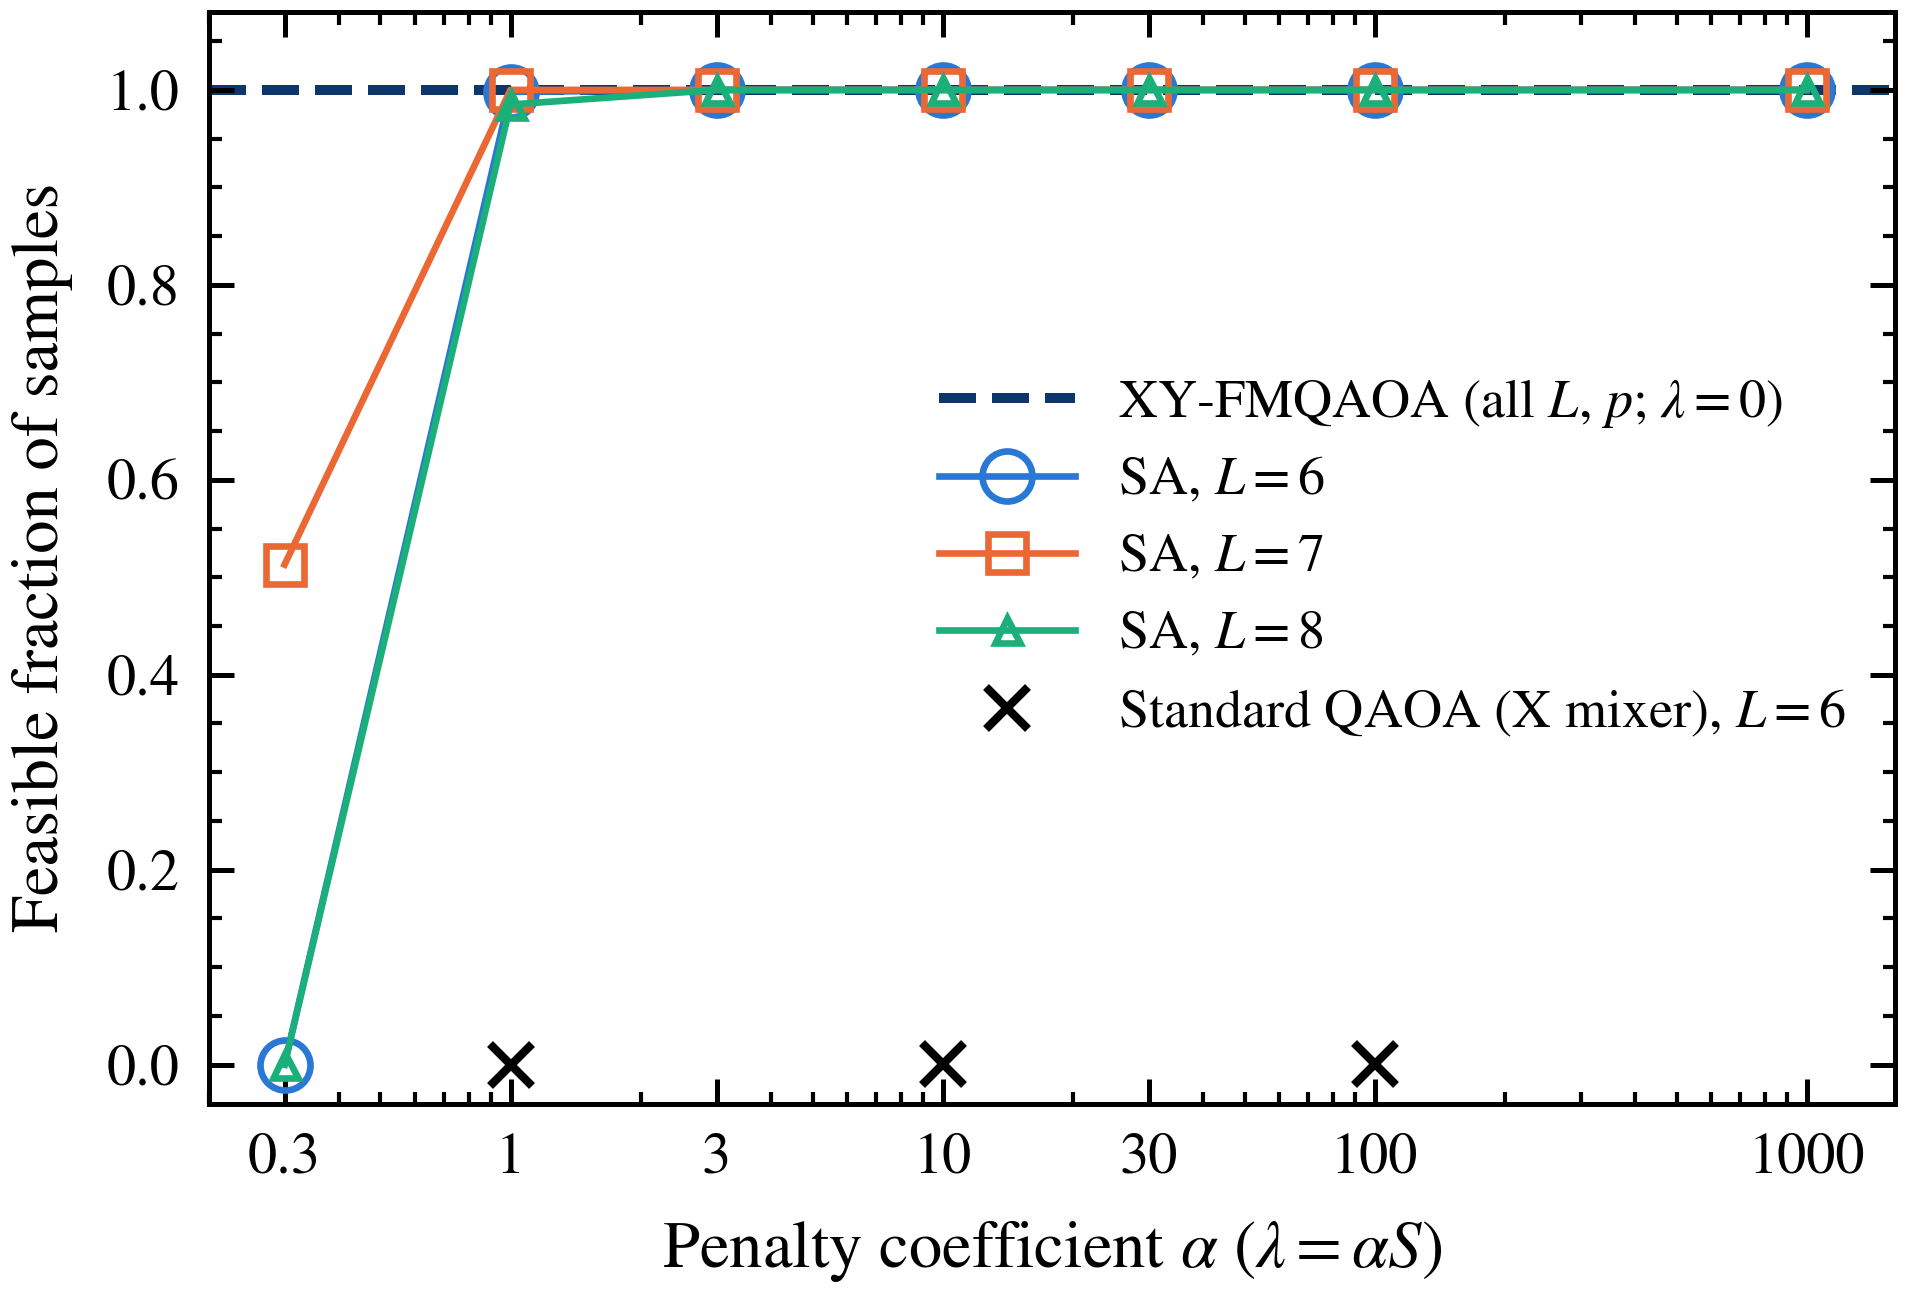

In [5]:
plot.fig_feasibility(); display(Image('png/penalty_feasibility.png'))

## 図 4b: One-Hot ペナルティ係数 α のスイートスポット(`penalty_sweetspot`, `penalty_sweetspot_combined`)

- 横軸: ペナルティ係数 α(対数)。λ = α S、S は FM の Ising 係数の最大絶対値
- 上段縦軸: 未評価の FM 最小解の捕捉率(capture rate、1 = 選ばれた候補が未評価 FM 最小解と一致)。5 FM の中央値と IQR 帯
- 下段縦軸: 100 サンプル中の制約充足率(Feasible fraction、1 = 全て有効)と、実行可能サンプルの FM 百分位の平均(Sample FM percentile、0 = FM 最良、0.5 = 一様ランダム相当)のトレードオフ
- `penalty_sweetspot` は L = 6, 7, 8 を別々の列に並べた 2×3 パネル図、`penalty_sweetspot_combined` は L = 6, 7, 8 を 1 つの軸に重ねた 2×1 統合図、個別 L の独立パネルは `panels/penalty_sweetspot_L{6,7,8}`
- 見るところ: α ≤ 0.3 では制約充足率が急落して違反解に陥り、α ≥ 10 ではエネルギー地形が平坦化してサンプル百分位が 0.5(ランダム)へ劣化する。結果として未評価 FM 最小解を捕捉できるスイートスポットは α ≈ 1〜3 の狭い範囲(緑帯)に限られる
- 限界: 5 FM(各 10 reps)の探索結果。Neal の自動温度範囲に基づく

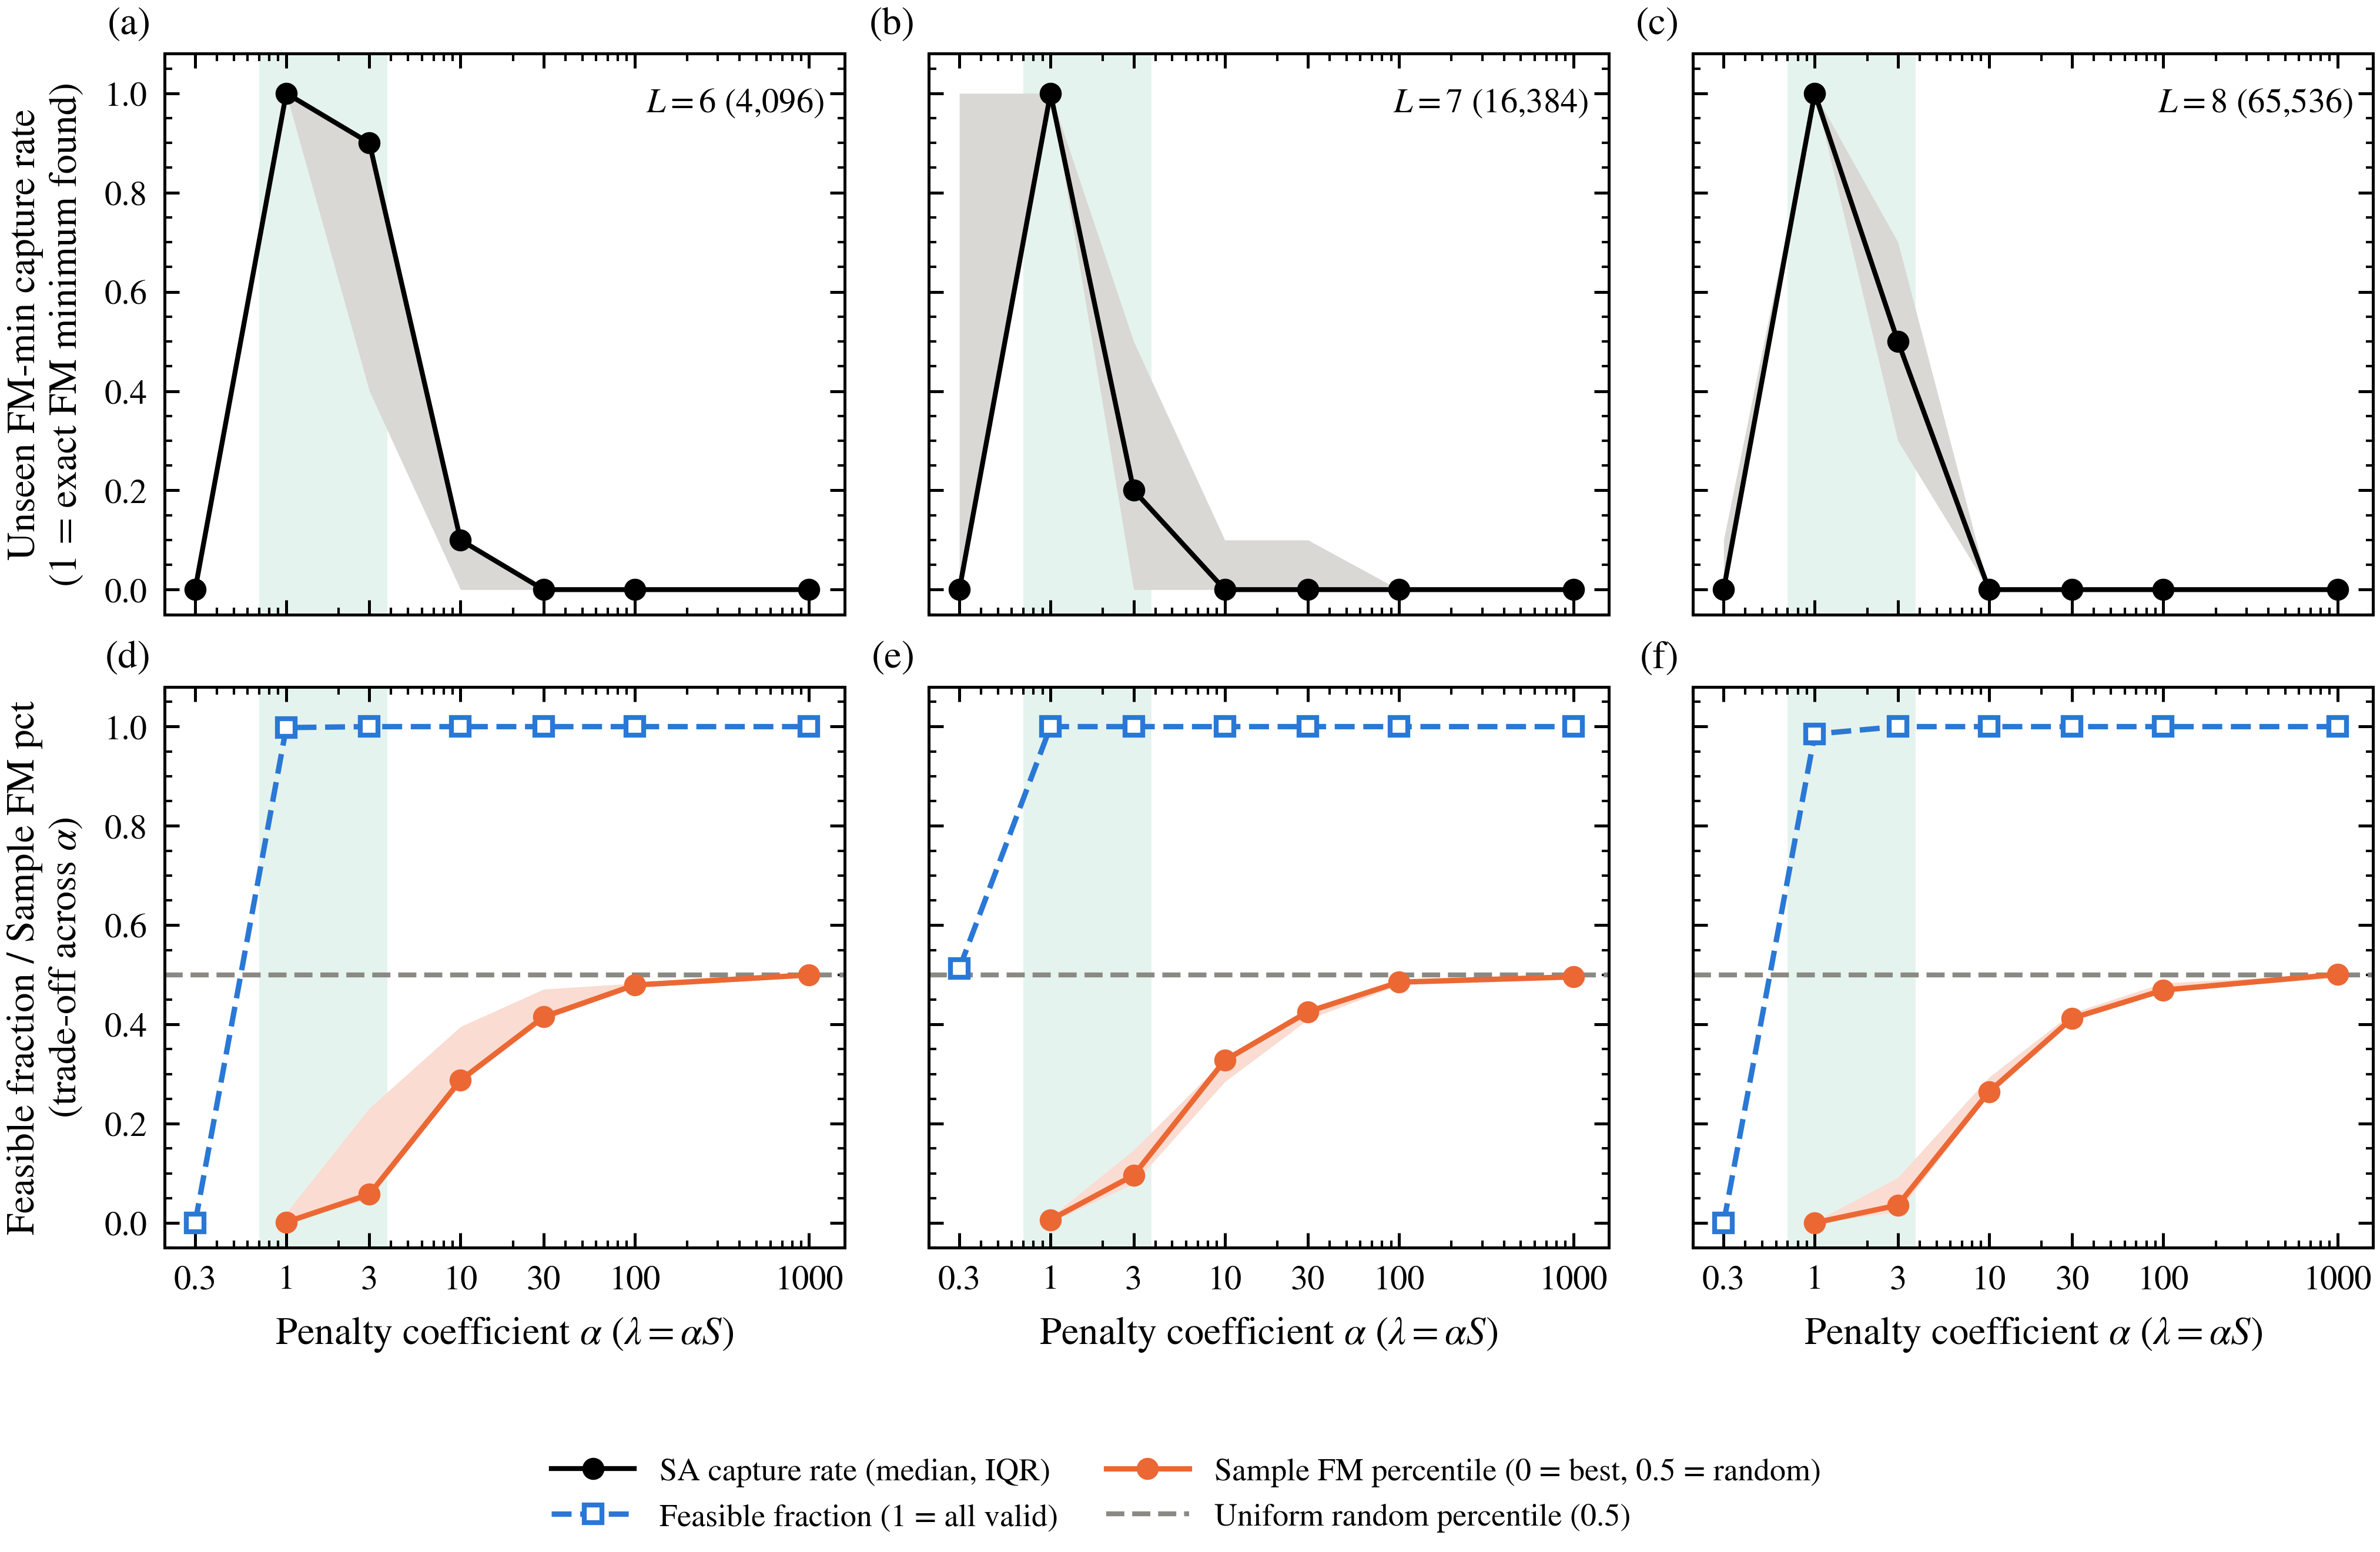

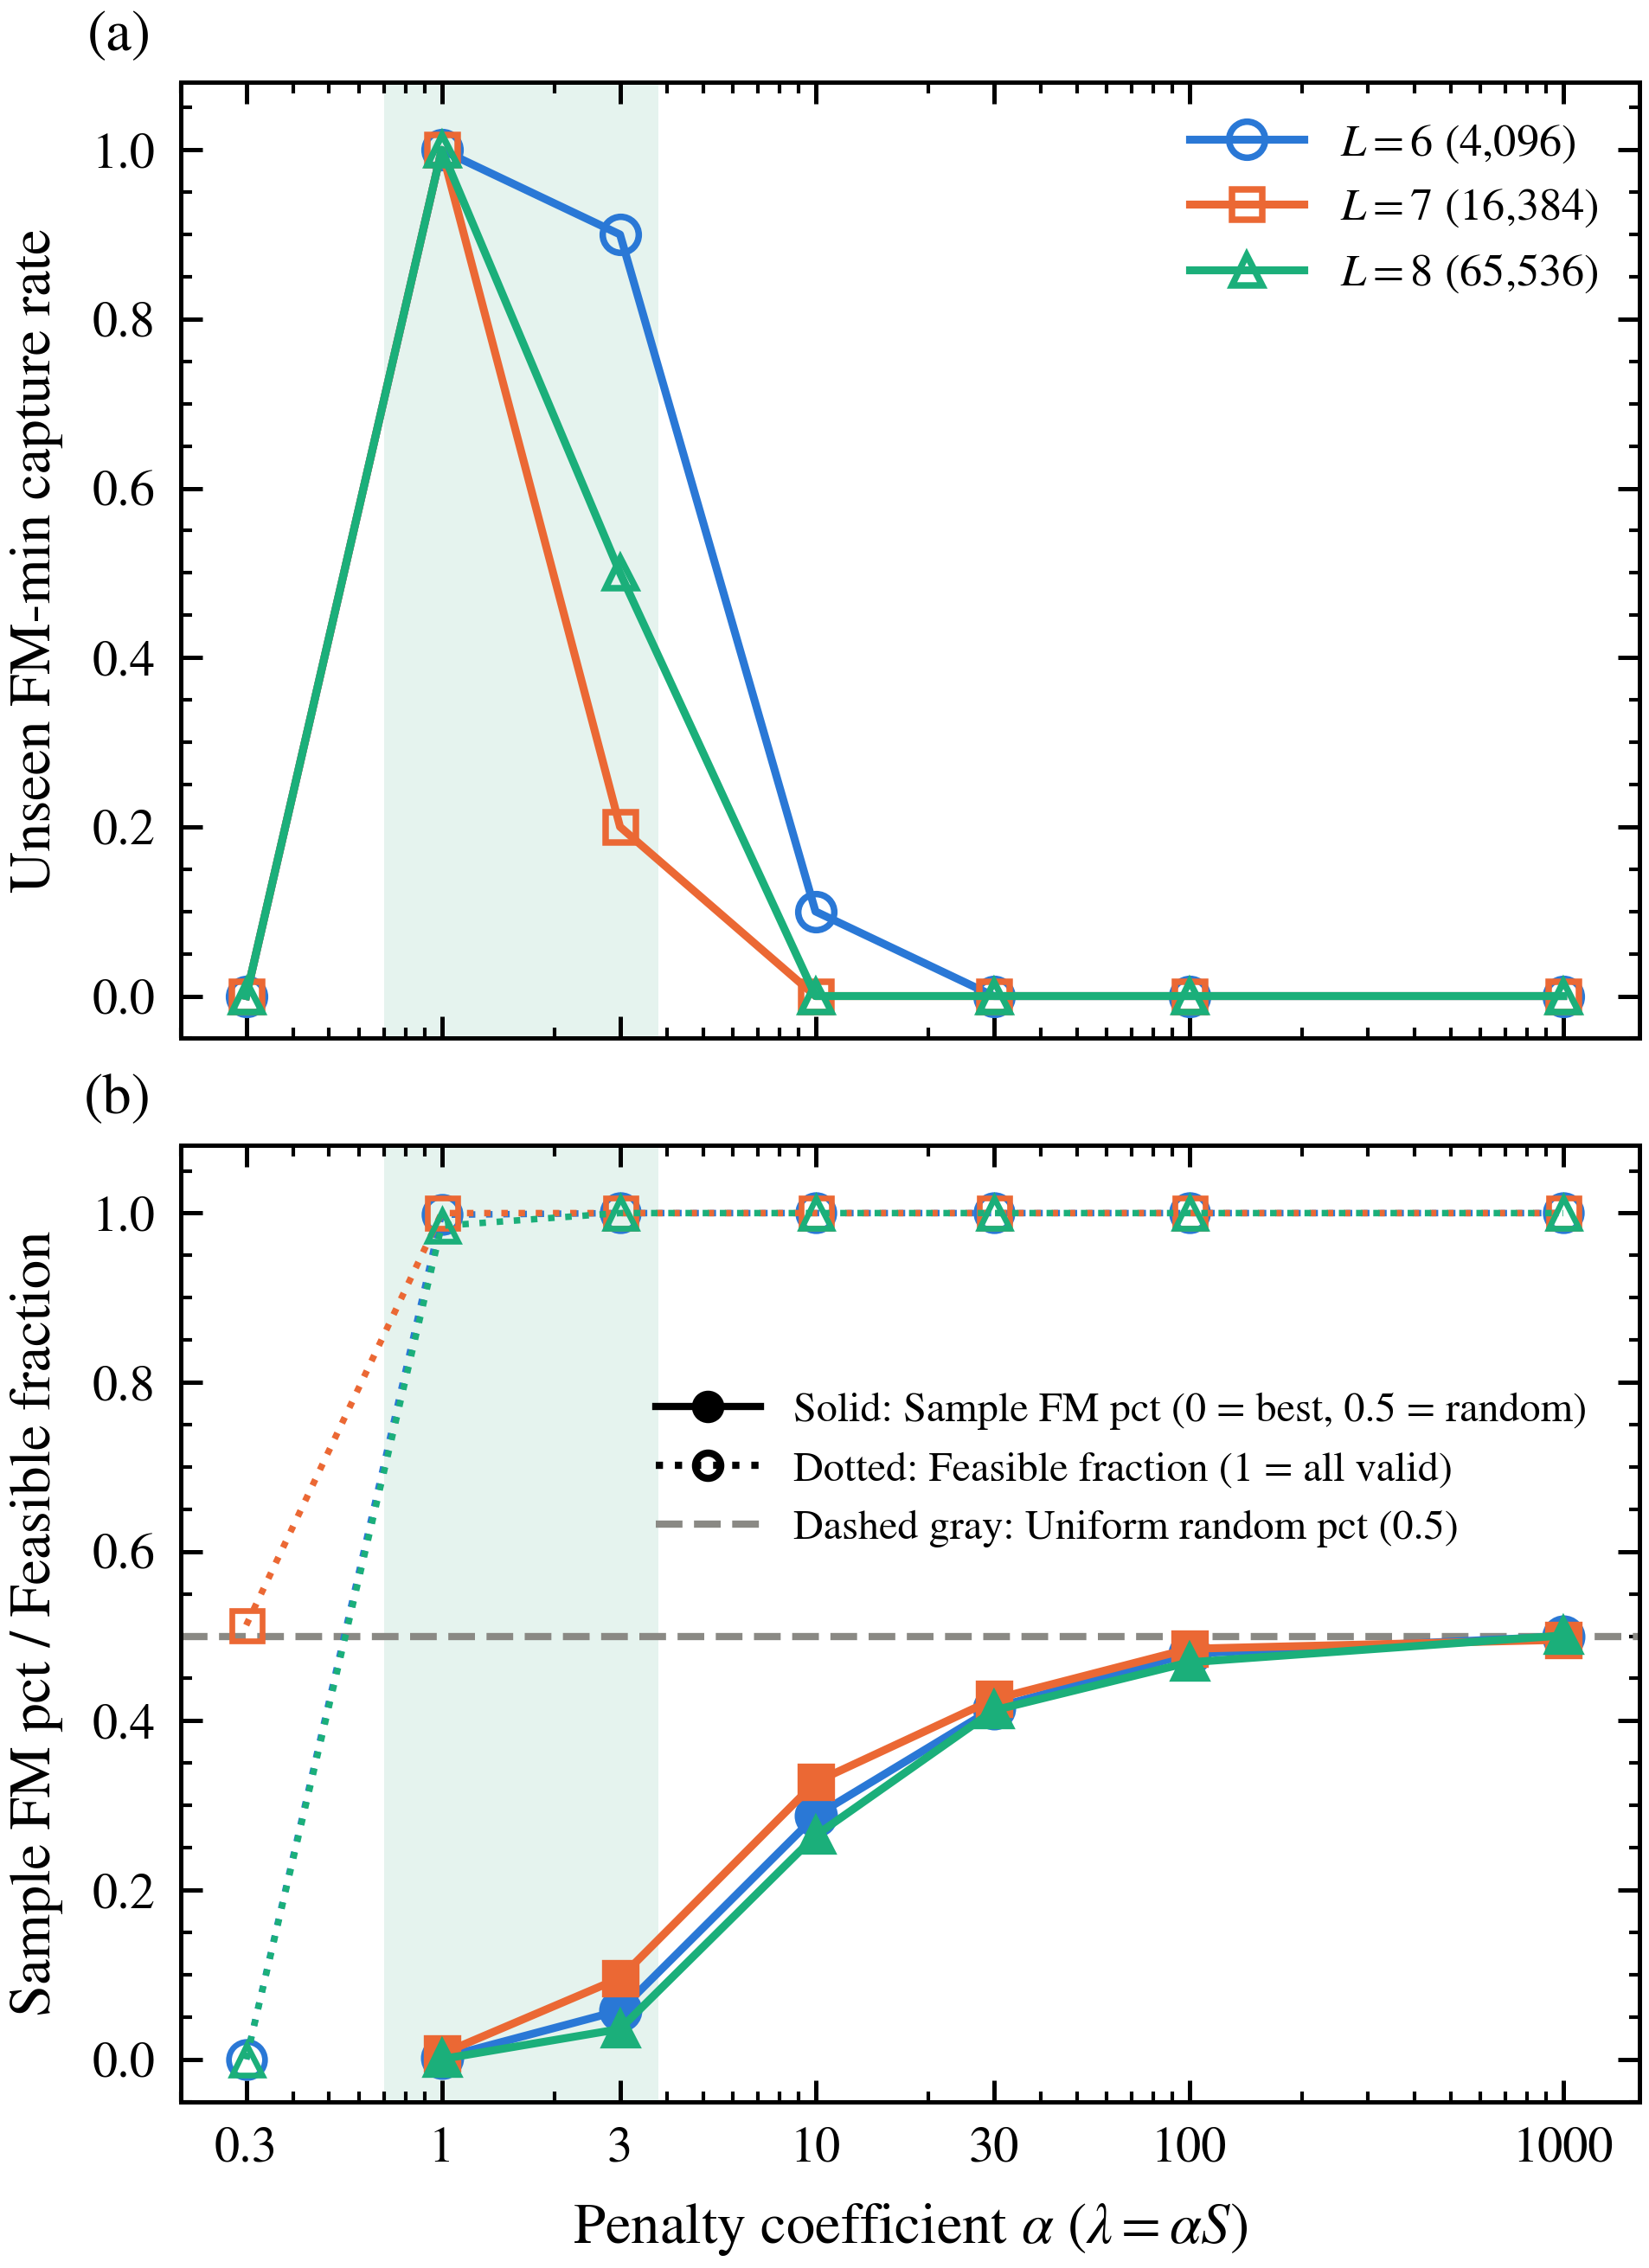

In [6]:
plot.fig_sweetspot()
display(Image(filename=str(HERE/'png/penalty_sweetspot.png'), width=900))
display(Image(filename=str(HERE/'png/penalty_sweetspot_combined.png'), width=450))

## 図 5: XY-FMQAOA の深さ p との関係(`xy_depth`)

- 横軸: XY-FMQAOA の深さ p(1〜6)。p=1〜3 は solver-fixedfm、p=4〜6 は solver-xydeep(p=3 の最良角度から継続、各深さ 1024 回の角度評価)
- 縦軸: 上段 (a)〜(c) は選ばれた候補の正規化 FM ギャップ(小さいほど良い)、下段 (d)〜(f) は実行可能なサンプルの FM 百分位の平均(0 = FM 最良、0.5 = ランダム)。列は L = 6, 7, 8
- 線: 濃い青の実線と塗りの丸 = CVaR$_{0.1}$ 目的(灰色の帯は 5 FM の IQR)、青の破線と中抜きの四角 = mean 目的。黒の水平線 = 同じ FM での SA(実線 α=1、破線 α=3、点線 α=10、一点鎖線 α=100)、灰色破線 = ランダム提案 + FM 選択
- 見るところ: XY は p=1→3 で大きく良くなるが、p=4〜6 ではほぼ横ばい(L=8 の CVaR は p=6 で少し悪化)。水準は SA の α=10 程度で、α=1〜3 には届かない。ギャップは CVaR 目的、サンプルの百分位は mean 目的の方が良い
- 限界: 角度の評価回数は深さによらず 1024 回で、深い回路ほど角度の最適化が不十分な可能性がある。5 FM の探索結果、理想シミュレーション

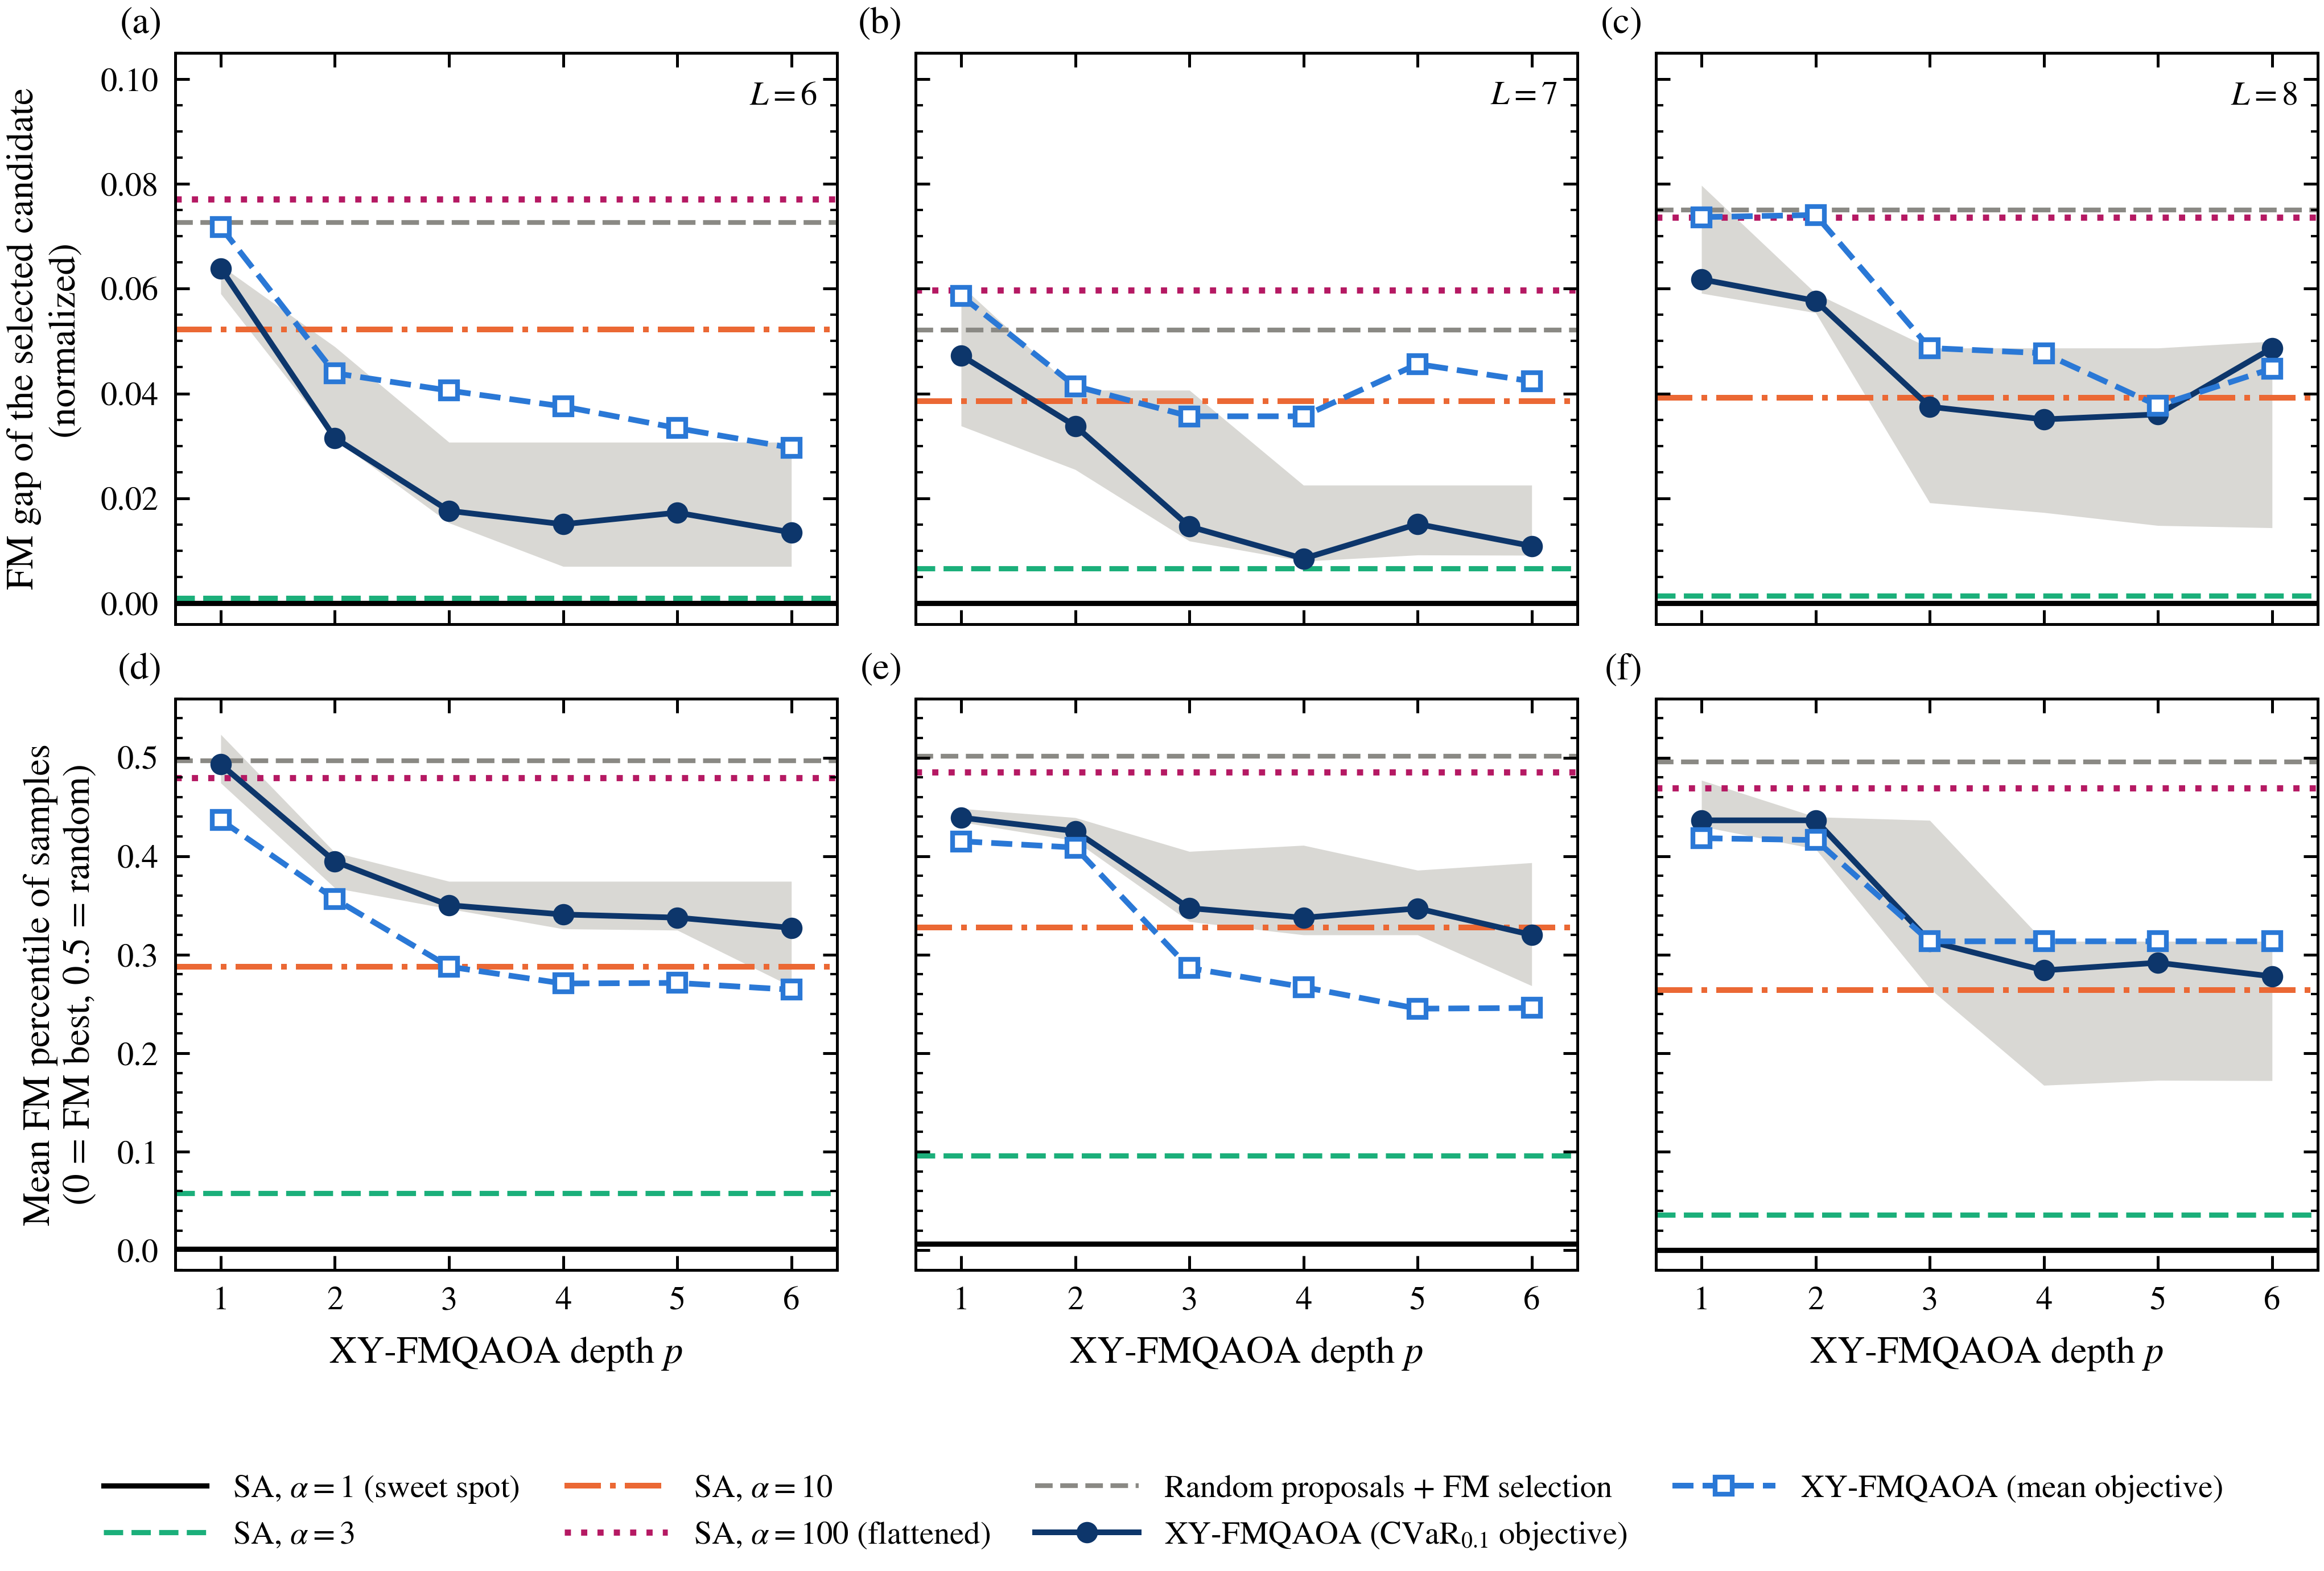

In [7]:
plot.fig_depth(); display(Image('png/xy_depth.png'))

### Lごとの上下2段図

`xy_depth_L6`、`xy_depth_L7`、`xy_depth_L8`。元図と同じ入力・軸範囲・色・線・5 FMの中央値/IQRで、各Lを独立に再描画。上段は正規化FMギャップ、下段はサンプルの平均FM百分位。今回の更新ではこの追加出力だけを生成し、既存セルは再実行していない。

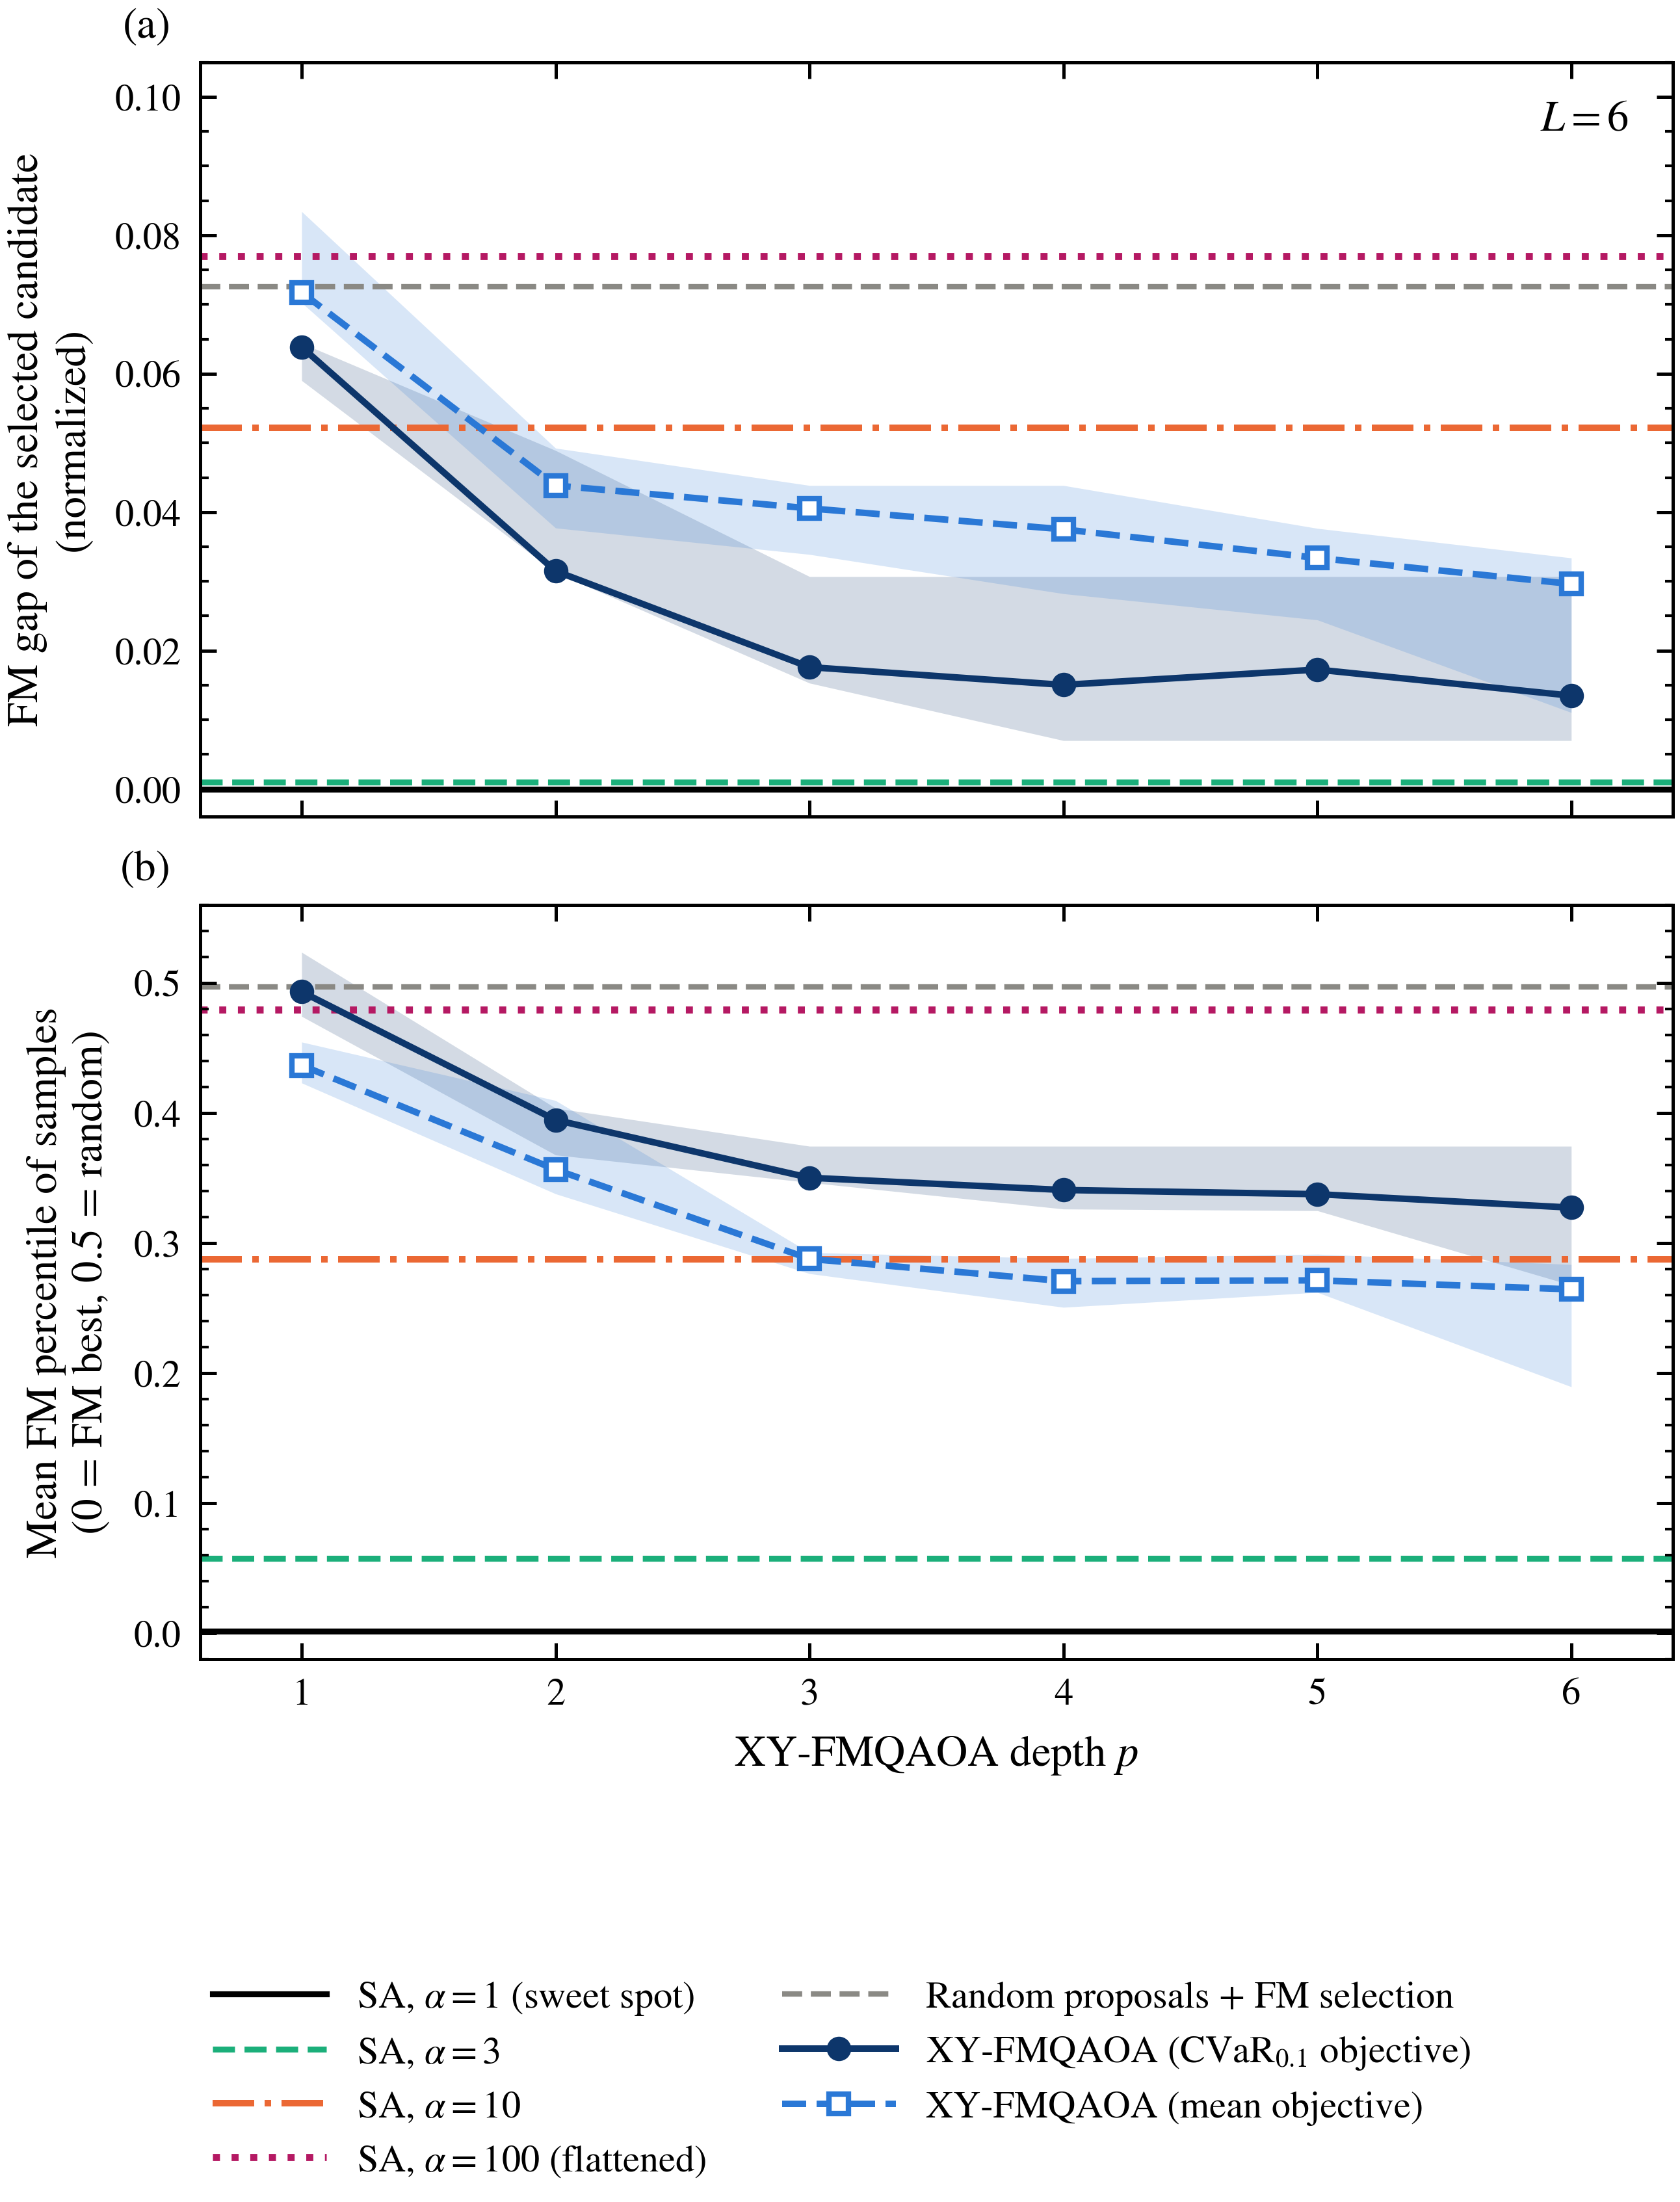

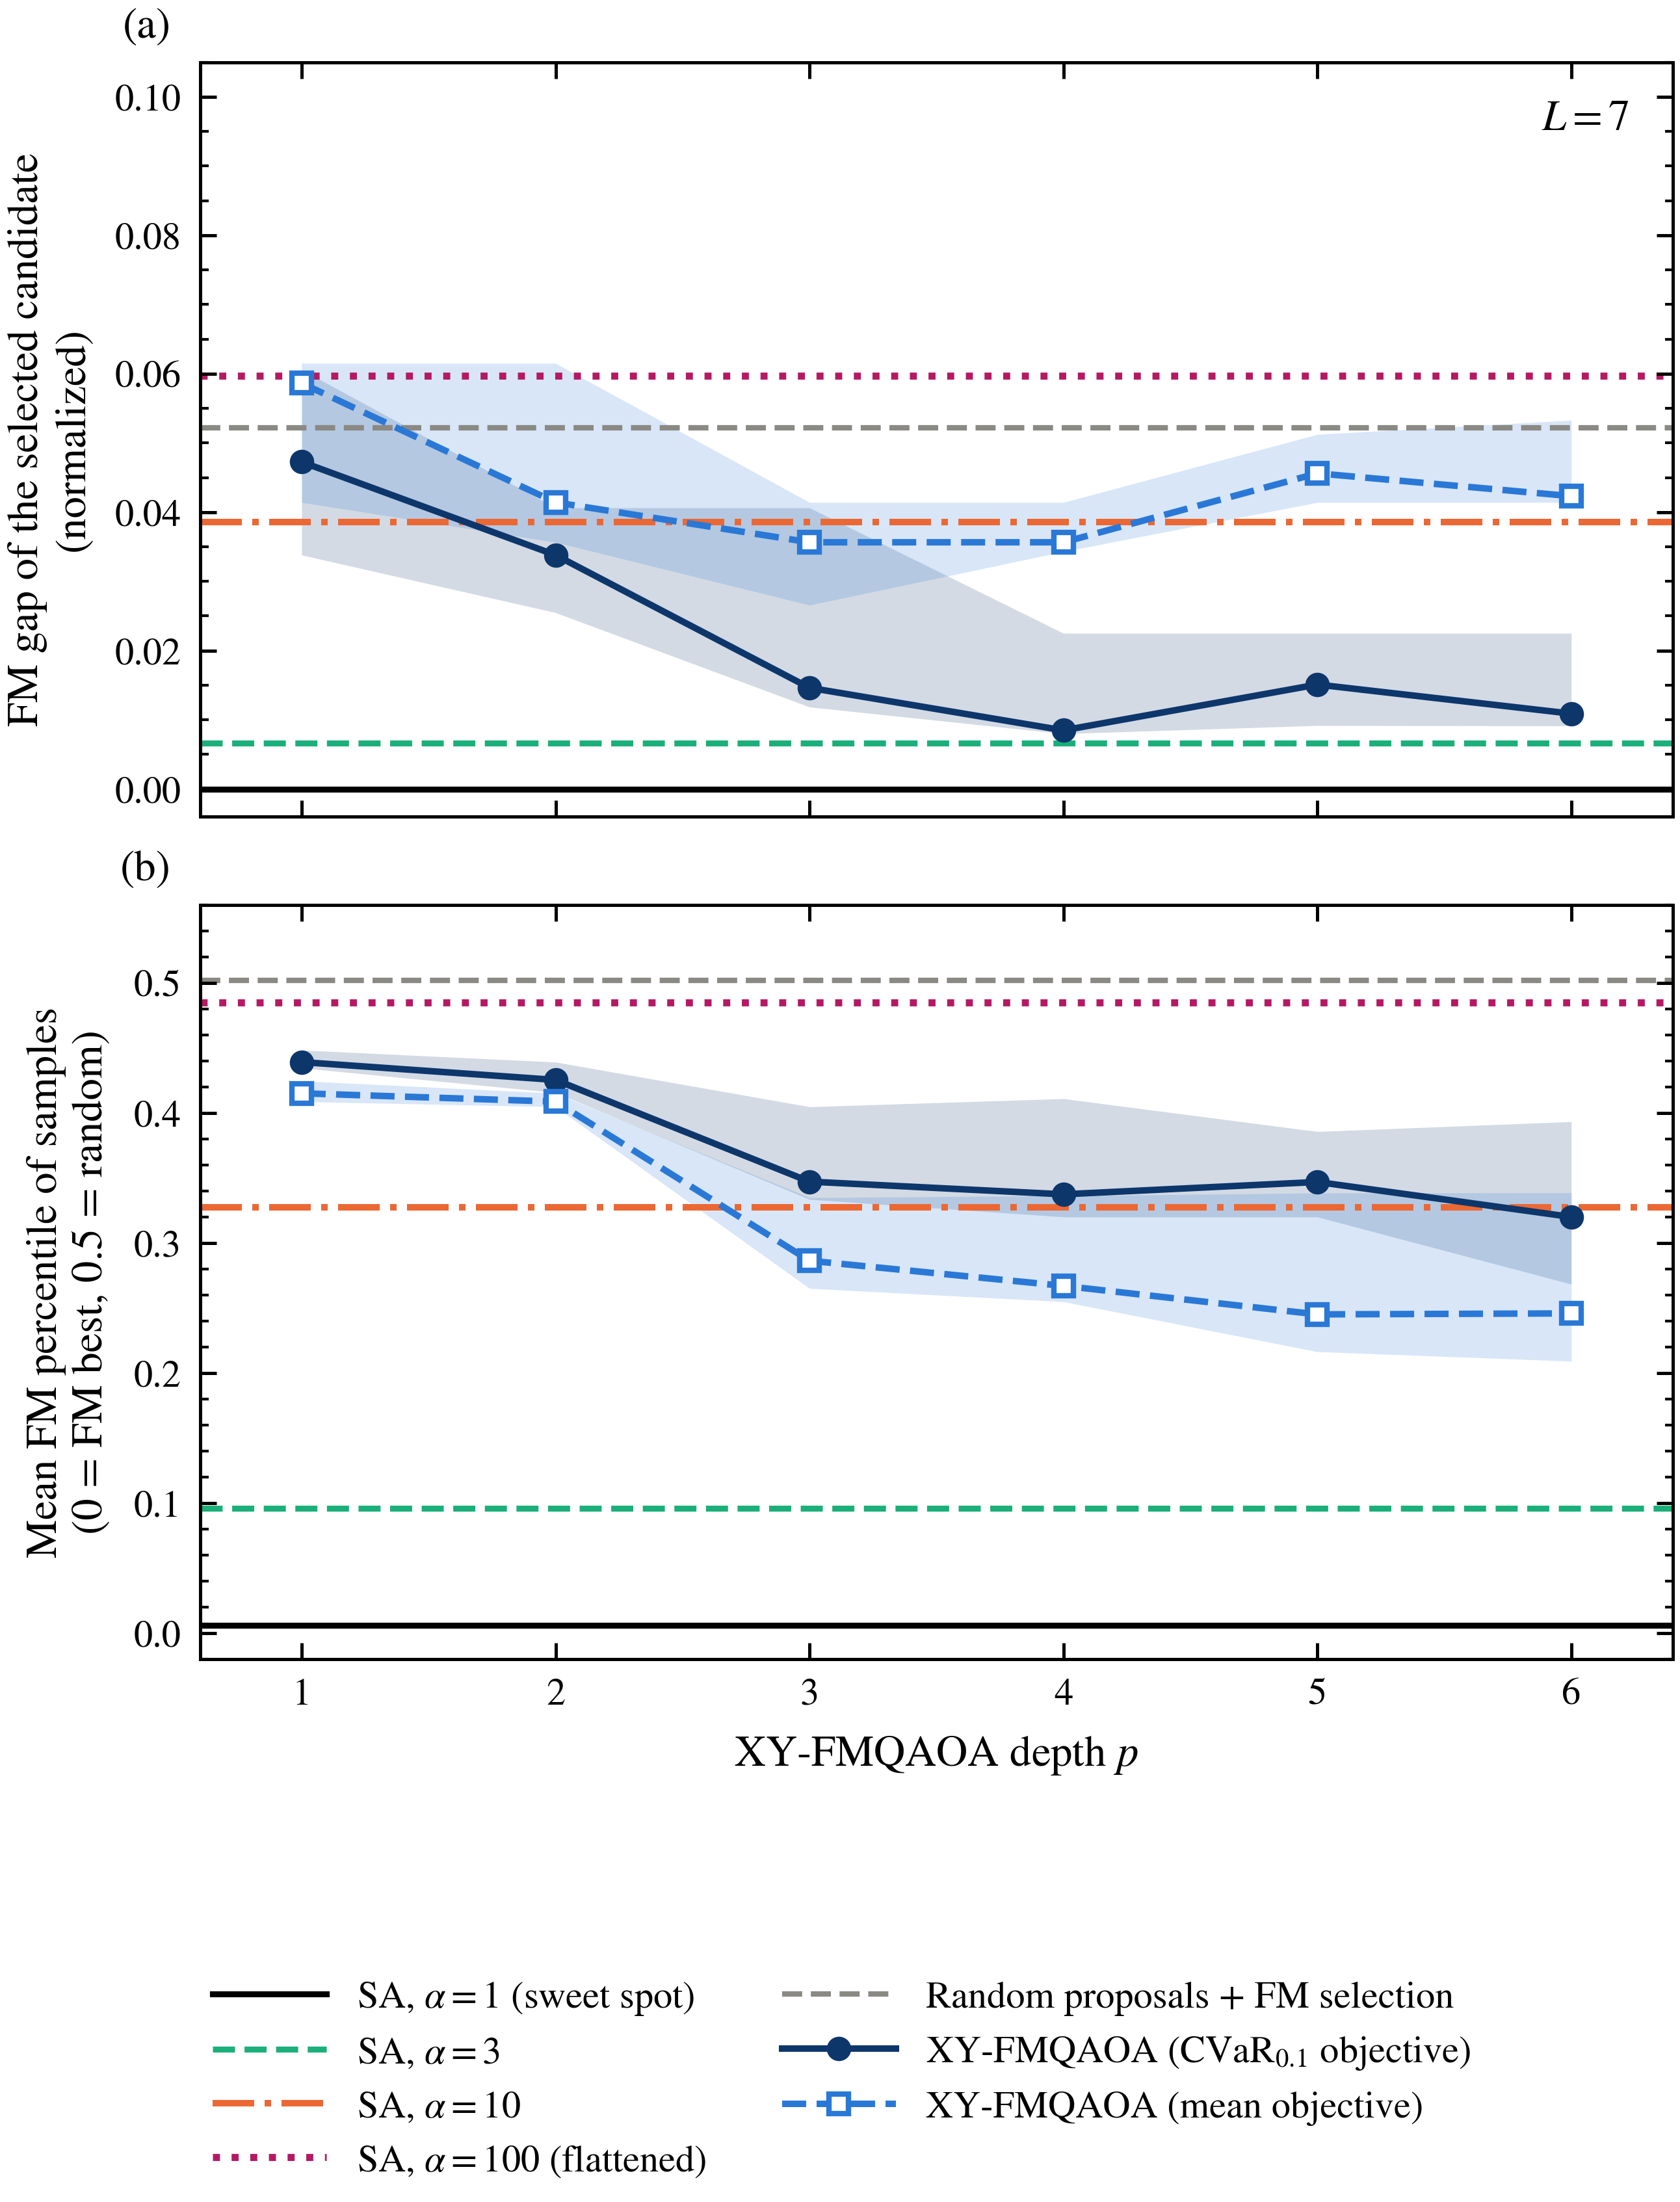

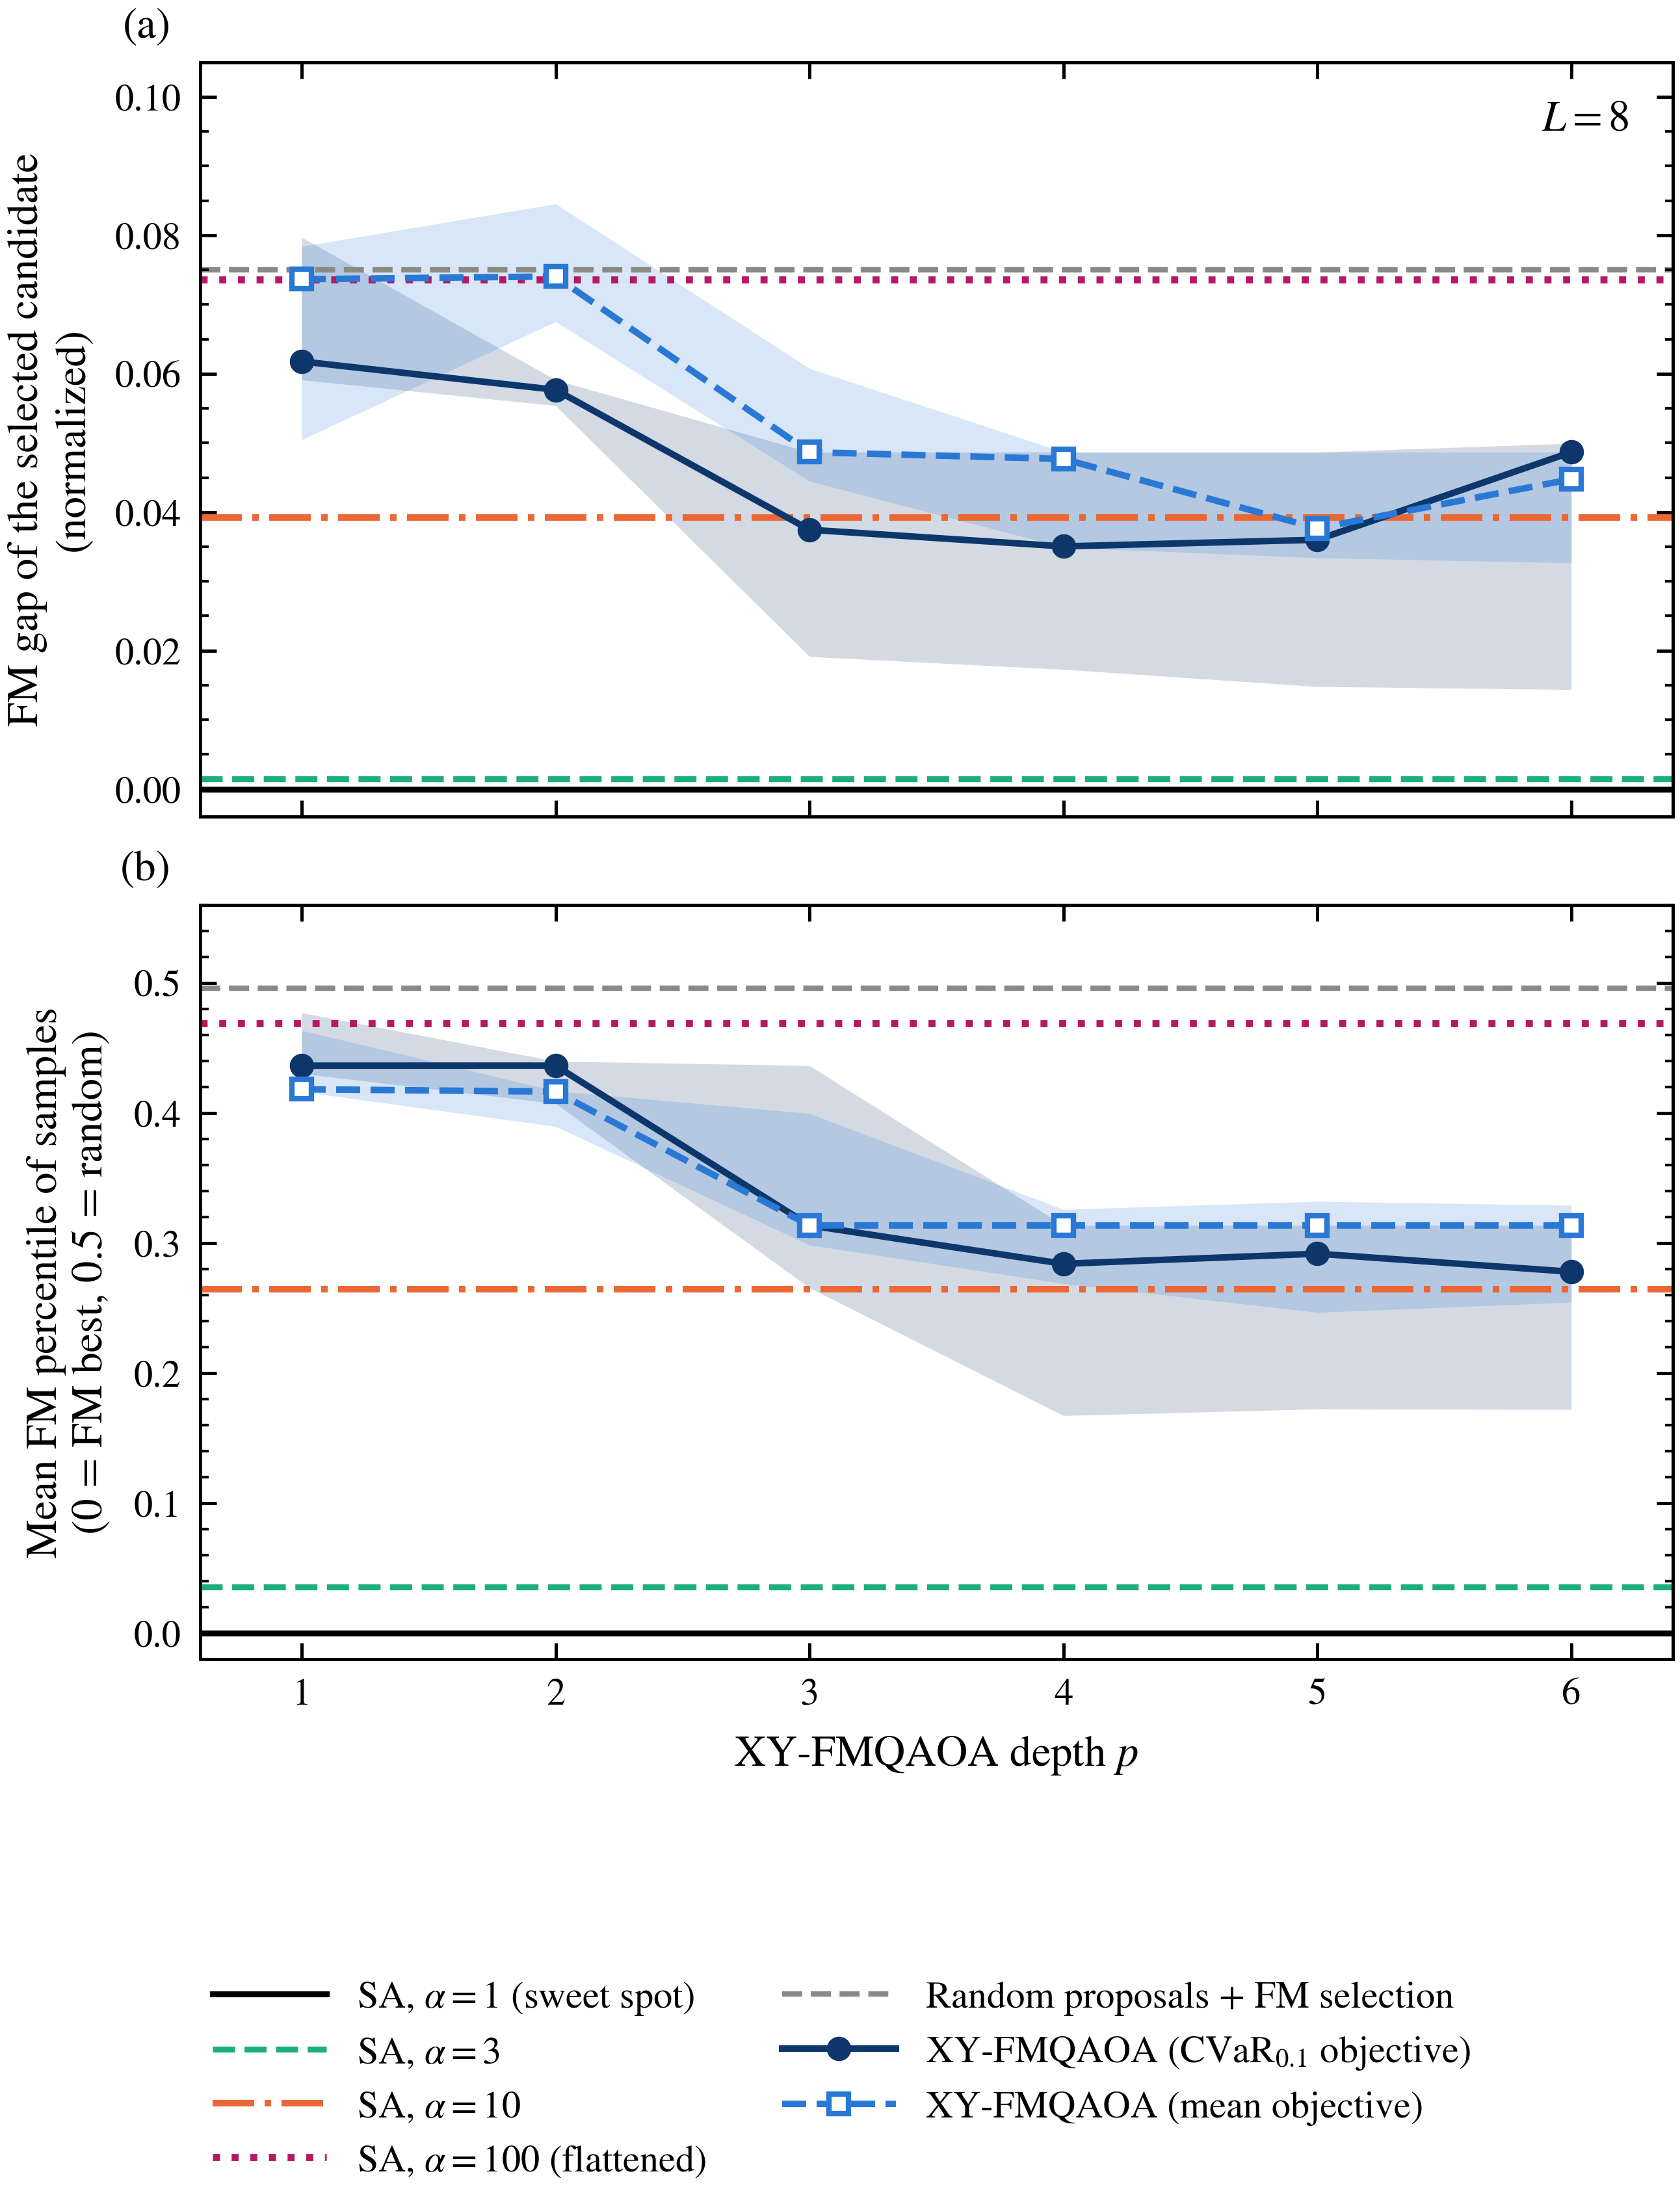

In [ ]:
plot.fig_depth_by_layer()
for L in plot.LAYERS:
    display(Image(f'png/xy_depth_L{L}.png'))

## 数値の確認(各 L、5 FM の中央値)

In [8]:
import csv
rows = plot.read('solver_summary.csv')
for L in plot.LAYERS:
    print(f'L={L}')
    for s in ['SA-a1','SA-a3','SA-a10','SA-a100','SA-a1000','RandomFM','XY-p1-cvar10','XY-p2-cvar10','XY-p3-cvar10','XY-p4-cvar10','XY-p5-cvar10','XY-p6-cvar10']:
        print(f"  {s:14s} sample_pct {plot.stat(rows,L,s,'sample_fm_pct')[0]:.3f}  norm_gap {plot.stat(rows,L,s,'norm_gap')[0]:.3f}  feasible {plot.stat(rows,L,s,'feasible')[0]:.2f}")

L=6
  SA-a1          sample_pct 0.002  norm_gap 0.000  feasible 1.00
  SA-a3          sample_pct 0.058  norm_gap 0.001  feasible 1.00
  SA-a10         sample_pct 0.288  norm_gap 0.052  feasible 1.00
  SA-a100        sample_pct 0.479  norm_gap 0.077  feasible 1.00
  SA-a1000       sample_pct 0.500  norm_gap 0.079  feasible 1.00
  RandomFM       sample_pct 0.497  norm_gap 0.073  feasible 1.00
  XY-p1-cvar10   sample_pct 0.493  norm_gap 0.064  feasible 1.00
  XY-p2-cvar10   sample_pct 0.395  norm_gap 0.031  feasible 1.00
  XY-p3-cvar10   sample_pct 0.350  norm_gap 0.018  feasible 1.00
  XY-p4-cvar10   sample_pct 0.341  norm_gap 0.015  feasible 1.00
  XY-p5-cvar10   sample_pct 0.338  norm_gap 0.017  feasible 1.00
  XY-p6-cvar10   sample_pct 0.327  norm_gap 0.013  feasible 1.00
L=7
  SA-a1          sample_pct 0.006  norm_gap 0.000  feasible 1.00
  SA-a3          sample_pct 0.096  norm_gap 0.007  feasible 1.00
  SA-a10         sample_pct 0.328  norm_gap 0.039  feasible 1.00
  SA-a100        

## 全図の保存(mean 版と独立パネルを含む)

In [9]:
plot.draw_all()
print(sorted(p.name for p in (HERE/'png').glob('*.png')))

figures written to /Users/hayashitaiga/Library/CloudStorage/GoogleDrive-taiga.hayashi@gmail.com/My Drive/Fujitsu_OpenQarp/analysis/mlfilter-scale/solver
['penalty_feasibility.png', 'penalty_flattening_cvar10.png', 'penalty_flattening_mean.png', 'penalty_mechanism.png', 'penalty_selected_gap_cvar10.png', 'penalty_selected_gap_mean.png', 'penalty_sweetspot.png', 'penalty_sweetspot_combined.png', 'xy_depth.png', 'xy_simple_failure.png', 'xy_simple_failure_combined.png']


## 図 5b: 簡単な XY-QAOA (p=1・49 格子・Mean 目的) の性能不足と深さ・CVaR 目的による改善(`xy_simple_failure`, `xy_simple_failure_combined`)

- 横軸: XY-FMQAOA の回路深さ p = 1〜6
- 上段縦軸: 選ばれた候補の正規化 FM ギャップ(0 = 未評価の FM 最小解と一致、小さいほど良い)
- 下段縦軸: 100 サンプルの FM 百分位の平均(0 = FM 最良、0.5 = 一様ランダム相当)
- `xy_simple_failure` は L = 6, 7, 8 を別々の列に並べた 2×3 パネル図、`xy_simple_failure_combined` は L = 6, 7, 8 を同一軸に重ねた 2×1 統合図、個別 L の独立パネルは `panels/xy_simple_failure_L{6,7,8}`
- 見るところ: 最も単純な p = 1(7×7 = 49 格子探索や Mean 目的、薄赤帯)では、正規化ギャップが 0.06〜0.08、サンプル百分位が 0.44〜0.49 に留まり、一様ランダム提案や平坦化した SA(α = 100)とほぼ同等の低い性能しか出ない。深さを p ≥ 3 に増やし CVaR0.1 目的と 1024 回探索を組み合わせることで初めて改善するが、それでもスイートスポットの SA(α = 1)の最適化精度には届かない
- 限界: 5 FM(各 10 reps)の探索結果。角度評価回数は p ≥ 1 で 1024 回固定

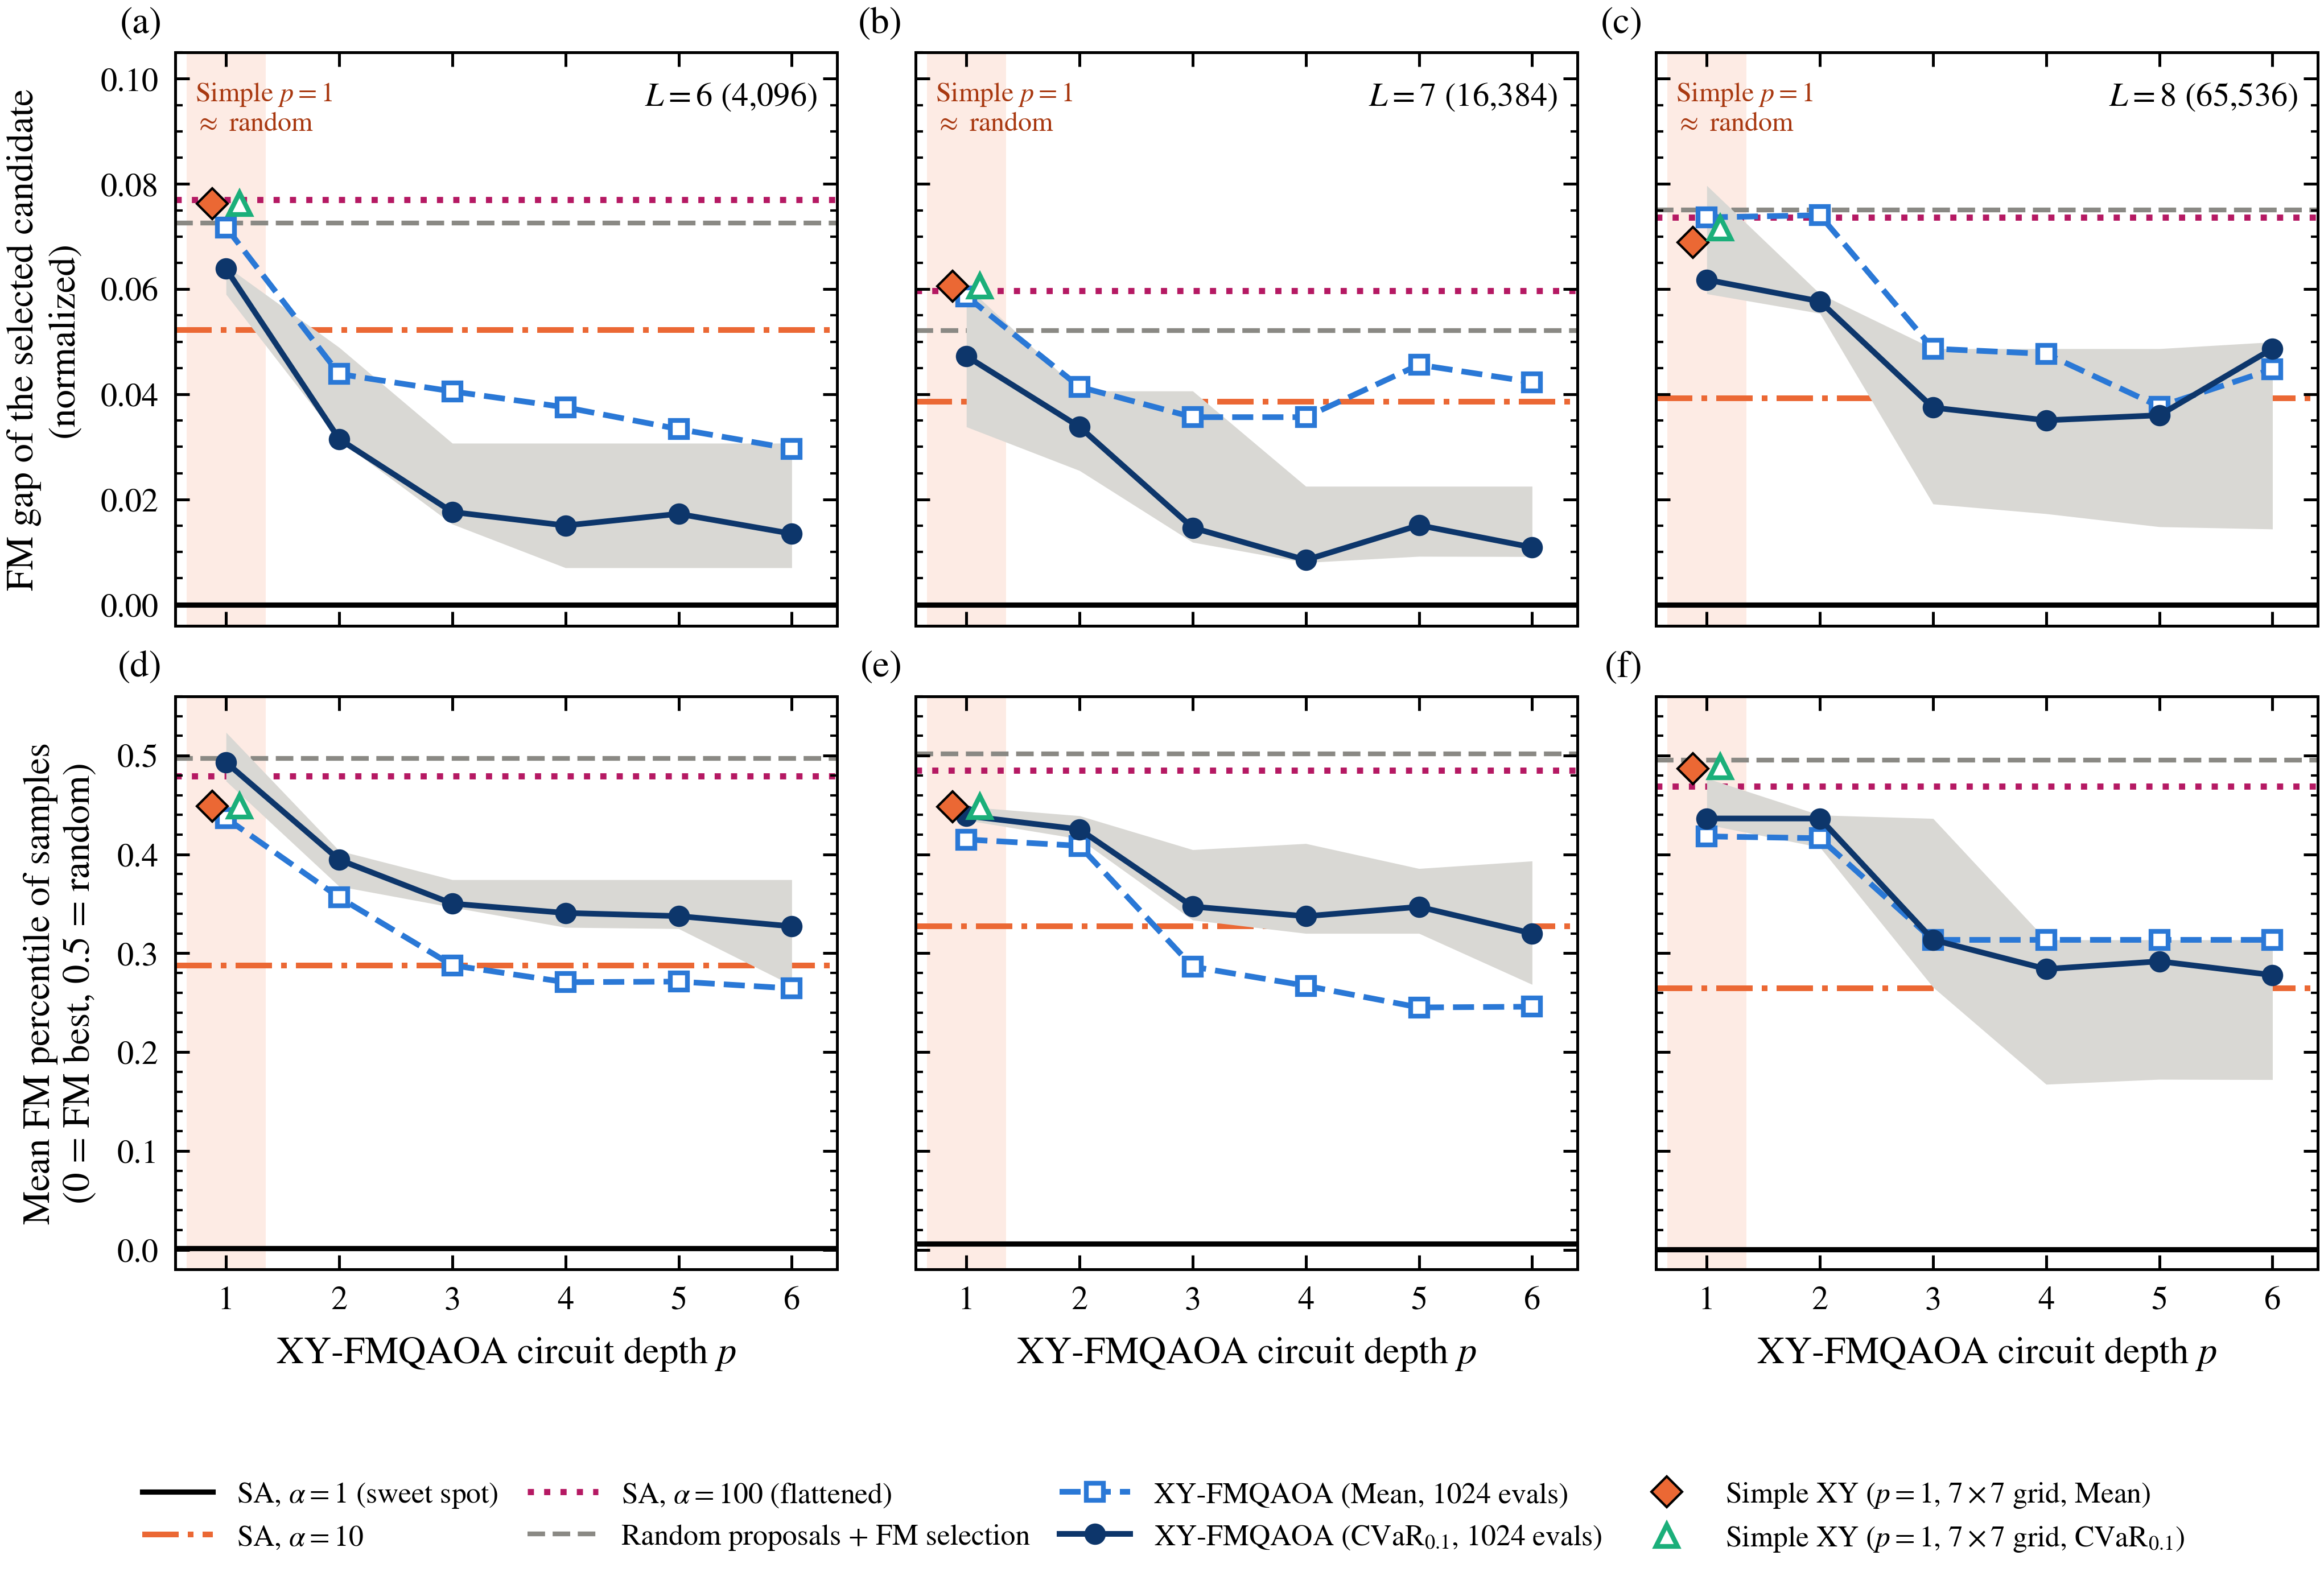

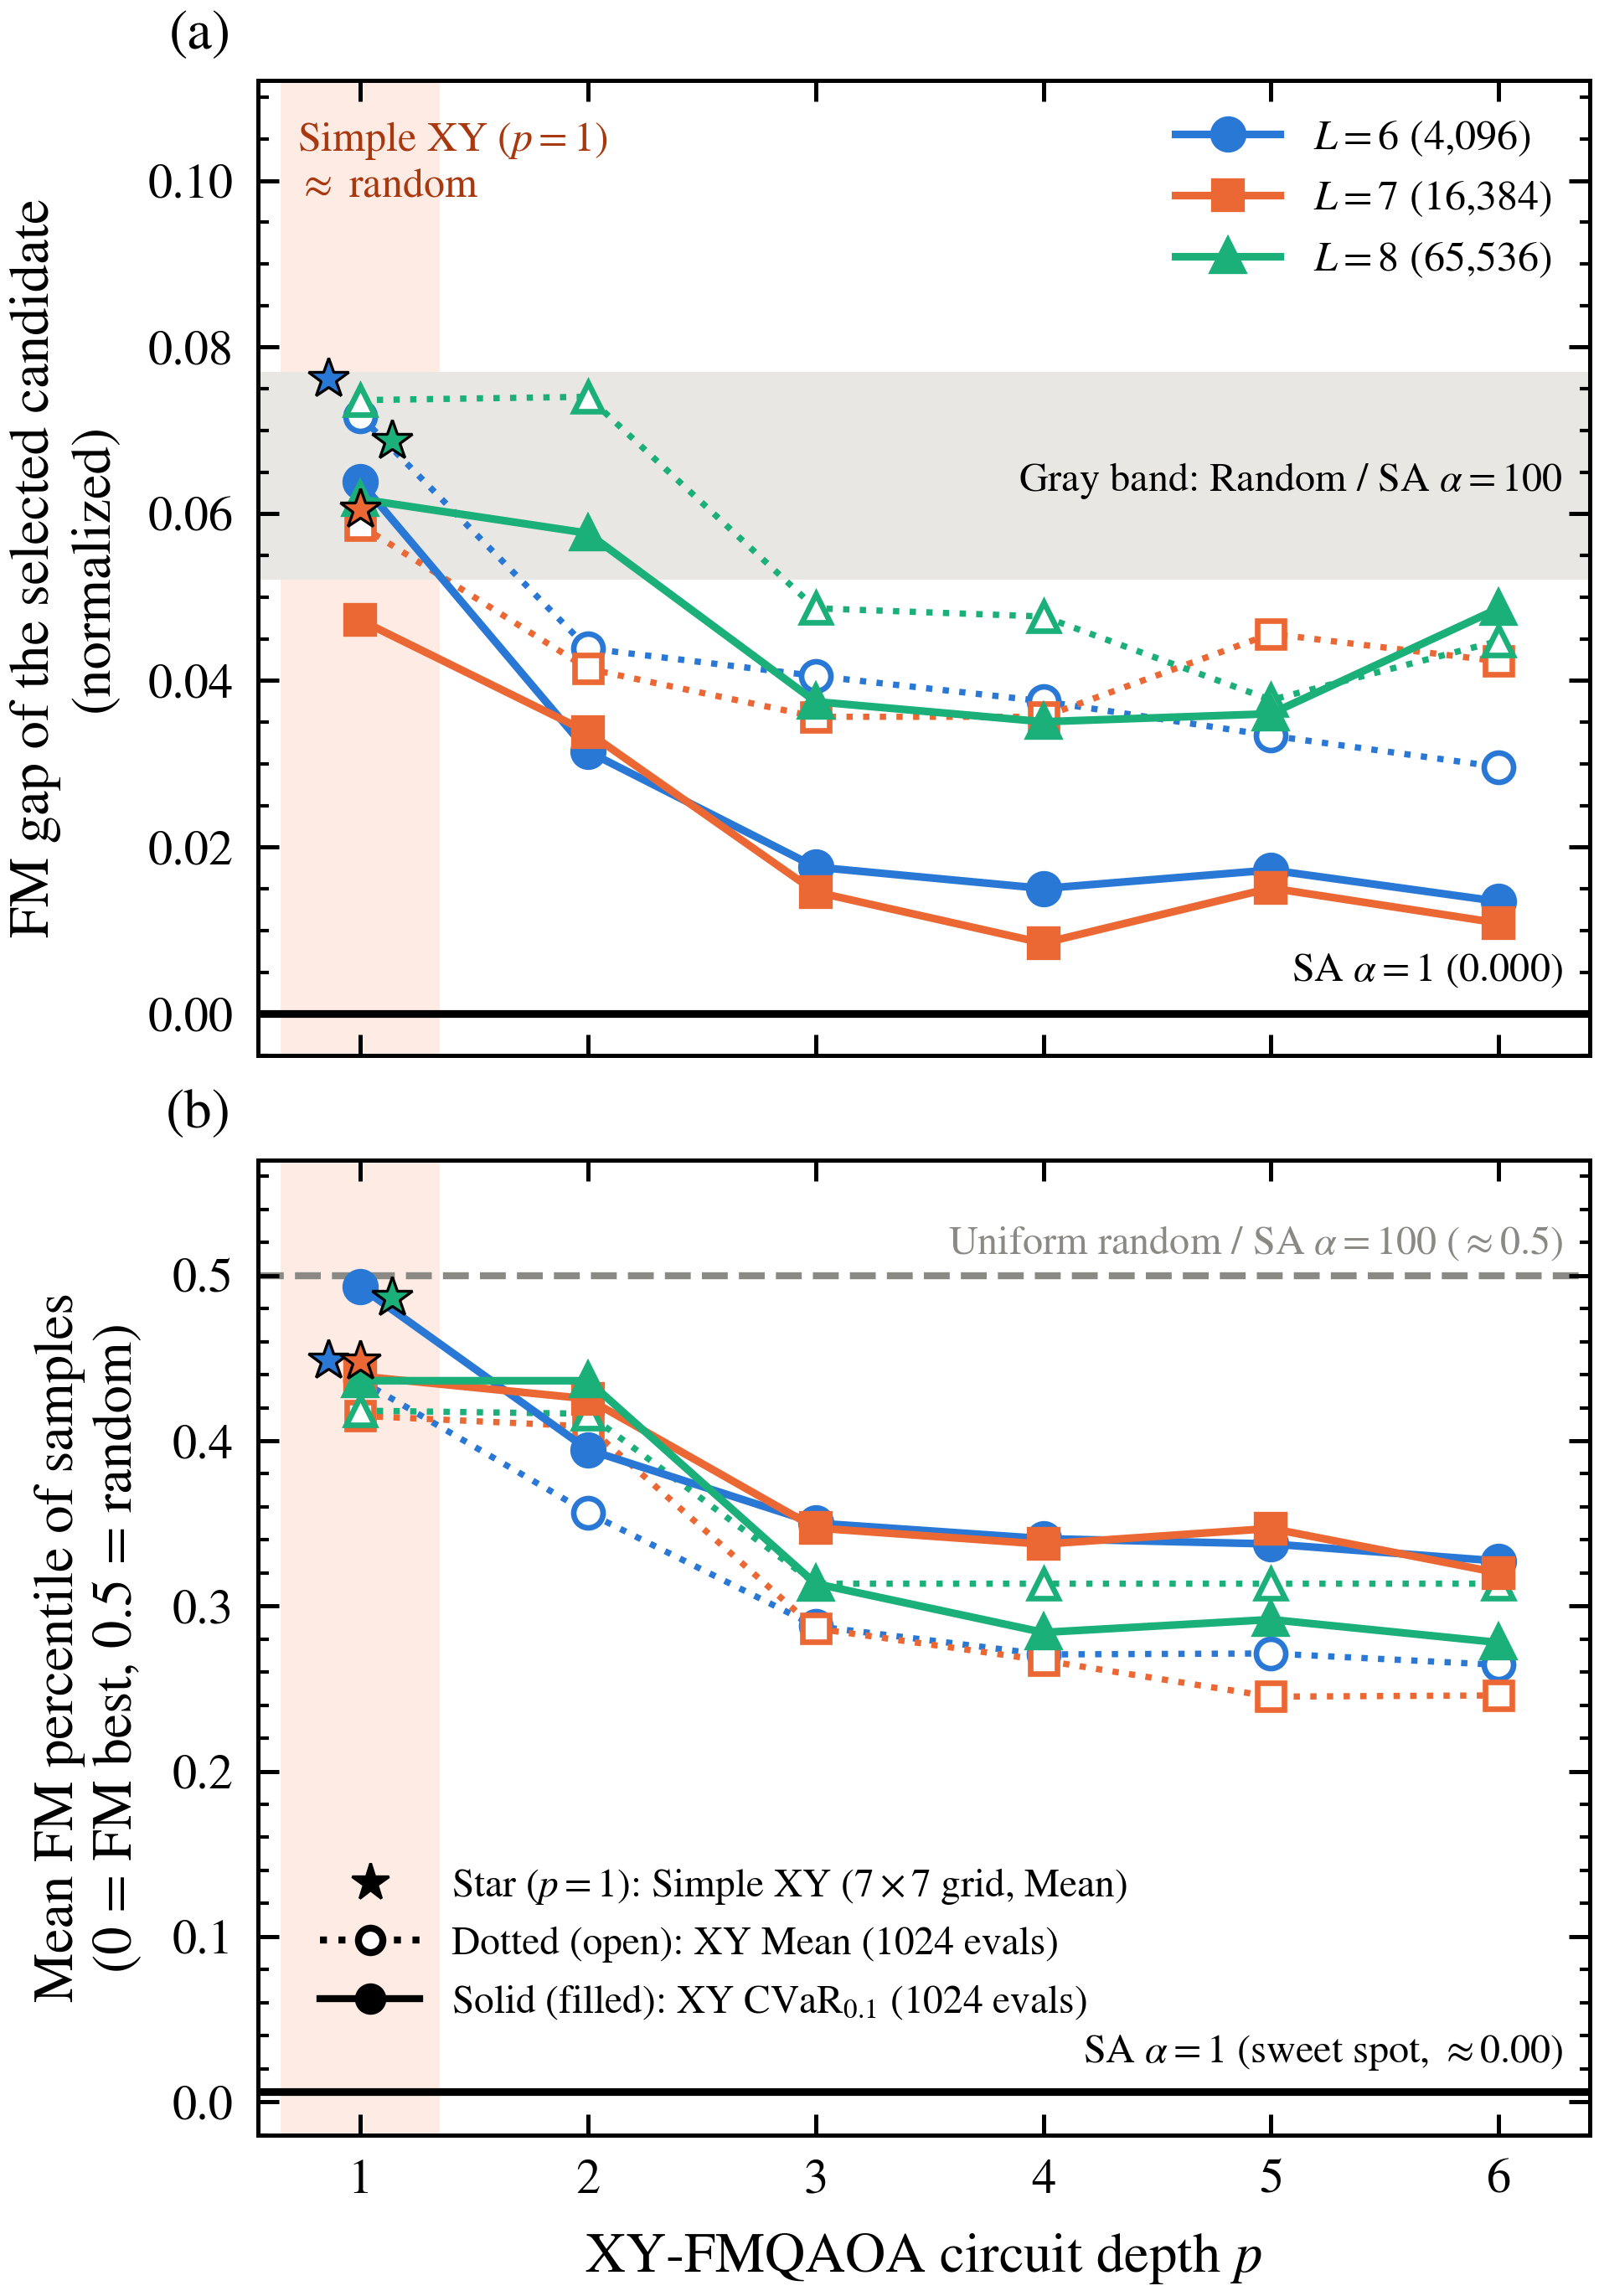

In [10]:
plot.fig_xy_simple_failure()
display(Image(filename='png/xy_simple_failure.png', width=620))
display(Image(filename='png/xy_simple_failure_combined.png', width=340))